# Predicción del puntaje global de la prueba Saber 11 a partir de variables socioeconómicas y del colegio

### Andrés Giovanny Rubiano Muñoz "Andy Rubiano"

**Maestría en Inteligencia Artificial**
**Universidad de La Salle**

**Ciencia de Datos**

---

**Actividad:** Proyecto Integrador de Ciencia de Datos | Fase 1 · Actividad 2: *Planteamiento del problema, objetivos y análisis exploratorio* (**Entregable 1**).

**Caso de estudio:** *Resultados únicos Saber 11*, publicado por el ICFES en el Portal Nacional de Datos Abiertos de Colombia (datos.gov.co). Se trabaja con el periodo **2022-4** (calendario A del segundo semestre de 2022), el más reciente y numeroso del conjunto.

**Dataset utilizado:** [`andyrubiano/saber-11-resultados-2022-4`](https://www.kaggle.com/datasets/andyrubiano/saber-11-resultados-2022-4) en Kaggle, copia en formato Parquet del periodo 2022-4 tomada del portal sin modificar ningún valor.

**Variable objetivo:** `punt_global`, el puntaje global del estudiante en la prueba (escala de 0 a 500).

**Variables explicativas candidatas:** características del estudiante (`estu_*`), del hogar (`fami_*`) y del colegio (`cole_*`).

**Licencia de los datos:** Creative Commons Attribution-ShareAlike 4.0 (CC BY-SA 4.0).

## 1. Planteamiento del problema

La prueba Saber 11 es el examen de Estado que presentan en Colombia todos los estudiantes que terminan la educación media, su puntaje global decide en buena medida el acceso a la educación superior, a becas como *Generación E* y a los programas de las universidades públicas, de modo que entender ¿qué factores ajenos al esfuerzo individual del estudiante se asocian con un puntaje alto o bajo?, es una pregunta con consecuencias directas sobre la equidad del sistema educativo.

El ICFES publica por cada aplicación un registro anónimo por estudiante con el resultado de la prueba y un cuestionario sociodemográfico que describe su hogar y su colegio. Ese registro permite plantear el problema como una tarea de aprendizaje supervisado de regresión, ya que el objetivo es predecir el puntaje global de un estudiante a partir de información que ya existe antes de presentar el examen.

### 1.1 Pregunta de investigación

¿En qué medida las características socioeconómicas del hogar, las características del colegio y las características demográficas del estudiante permiten predecir el puntaje global de la prueba Saber 11 y cuáles de esas características tienen mayor peso?

### 1.2 Objetivos

**Objetivo general.** Construir y evaluar un modelo de regresión que prediga el puntaje global de la prueba Saber 11 (periodo 2022-4) a partir de variables socioeconómicas, familiares y del colegio e interpretar la contribución de cada grupo de variables.

**Objetivos específicos.**

1. Describir el conjunto de datos *Resultados únicos Saber 11* (origen, licencia, variables, tamaño, calidad) y caracterizar la distribución de la variable objetivo.
2. Identificar, mediante análisis exploratorio las variables con mayor asociación con el puntaje global y las que deben excluirse por fuga de información o por falta de valor predictivo.
3. Preparar los datos (tratamiento de valores faltantes, codificación de variables ordinales y nominales, ingeniería de variables) y establecer un modelo de referencia (*baseline*) con su métrica inicial.
4. Entrenar y comparar al menos dos modelos adicionales al de referencia, ajustar sus hiperparámetros con validación cruzada y evaluarlos con métricas apropiadas para regresión (MAE, RMSE y R²).
5. Interpretar el modelo final (importancia de variables, análisis de errores) y comunicar los resultados mediante visualizaciones, un informe técnico y una sustentación.

Este cuaderno cubre los objetivos específicos 1 y 2 que corresponden a la **Fase 1** del proyecto.

### 1.3 Hipótesis de trabajo

- **H1.** El nivel socioeconómico del hogar (estrato, educación de los padres, acceso a internet y computador) es el grupo de variables con mayor asociación con el puntaje global.
- **H2.** Las características del colegio (naturaleza oficial o privada, área urbana o rural, jornada, calendario) aportan información adicional a la del hogar.
- **H3.** Existe una brecha regional, el departamento donde se ubica el colegio explica parte de la variación del puntaje, incluso después de considerar el hogar y el colegio.

### 1.4 Alcance y restricciones

- El problema se trata como regresión sobre `punt_global`. Los puntajes por área (`punt_matematicas`, `punt_lectura_critica`, `punt_sociales_ciudadanas`, `punt_c_naturales`, `punt_ingles`) y el nivel de inglés (`desemp_ingles`) no pueden usarse como variables explicativas, porque el puntaje global se calcula a partir de ellos e incluirlos sería una fuga de información (*data leakage*).
- Se usa un único periodo (2022-4) para evitar mezclar escalas y cuestionarios de distintos años y para mantener el volumen manejable en Google Colab.
- El análisis es correlacional, ya que tiene como objetivo identificar asociaciones útiles para predecir relaciones no causales.

## 2. Preparación del entorno

El cuaderno está diseñado para ejecutarse en **Google Colab** sin instalación adicional, puesto que todas las dependencias (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn` y `kagglehub`) vienen preinstaladas, también corre de forma local sobre el repositorio del proyecto con `pip install -r requirements.txt`.

Se importan las librerías agrupadas por propósito:

*   **Utilidades estándar** (`os`, `sys`, `time`, `warnings`, `pathlib`): rutas, tiempos y silenciamiento de advertencias.
*   **Manipulación de datos** (`numpy`, `pandas`): carga, transformación y agregación del conjunto.
*   **Visualización** (`matplotlib`, `seaborn`): todas las figuras del análisis exploratorio.
*   **Estadística** (`scipy.stats`): correlación de Spearman y pruebas de asociación.
*   **Descarga de datos** (`kagglehub`): se importa dentro de la celda de carga de la sección 3.

Al final se resuelven las rutas del proyecto. Si el cuaderno corre dentro del repositorio, `PROJECT_ROOT` apunta a su raíz y las figuras se guardan en `assets/images/data/`, que es de donde las toma el informe, en Colab se crea la misma estructura bajo `/content/saber11-project`.

Para facilitar la ejecución sin importar el entorno, el conjunto de datos se importa utilizando `kagglehub`.

In [18]:
import os, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import scipy
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

print("pandas:", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__,
      "| seaborn:", sns.__version__, "| scipy:", scipy.__version__)

IN_COLAB = "google.colab" in sys.modules

def find_project_root(start=Path.cwd()):
    """Sube por el árbol de carpetas hasta encontrar la raíz del repositorio (README.md + notebooks/)."""
    for candidate in [start, *start.parents]:
        if (candidate / "README.md").exists() and (candidate / "notebooks").is_dir():
            return candidate
    return start

PROJECT_ROOT = Path("/content/saber11-project") if IN_COLAB else find_project_root()
FIG_DIR = PROJECT_ROOT / "assets" / "images" / "data"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"Entorno        : {'Google Colab' if IN_COLAB else 'local'}")
print(f"Raíz del proyecto: {PROJECT_ROOT}")

pandas: 3.0.6 | numpy: 2.5.4 | matplotlib: 3.11.2 | seaborn: 0.13.2 | scipy: 1.18.1
Entorno        : local
Raíz del proyecto: d:\Universidad de La Salle\2do semestre\Ciencia de datos\Proyecto final\saber11-project


Luego se define la identidad gráfica de todas las visualizaciones del cuaderno, de modo que compartan paleta, tipografía y estilo:

*   **Paleta de colores**: un azul (`C_BASE`) para la variable objetivo y las series principales, un naranja (`C_ACCENT`) para contrastes, un tono neutro (`C_NEU`) para descripciones del conjunto y tonos de tinta y gris para textos y ejes. Para las variables ordinales (estrato, educación de los padres) se usa una escala secuencial (`CMAP_SEQ`) en la que un tono más oscuro significa un nivel más alto.
*   **Configuración global** (`plt.rcParams` y `seaborn`): cuadrícula sutil, sin bordes superior ni derecho, títulos en negrilla alineados a la izquierda y 110 dpi.
*   **Semilla global** `RANDOM_STATE = 42`, que gobierna cualquier muestreo del cuaderno.
*   **Función `save_fig`**: guarda cada figura en `assets/images/data/` con el nombre que después cita el informe.

In [19]:
C_BASE, C_ACCENT, C_NEU = "#2a78d6", "#eb6834", "#5B7C99"
TINTA, GRIS = "#0b0b0b", "#52514e"
PALETTE = [C_BASE, C_ACCENT, "#2CA02C", "#9467BD", "#8C564B", "#E377C2", "#7F7F7F", "#BCBD22"]
CMAP_SEQ = "Blues"

sns.set_style("whitegrid")
sns.set_palette(PALETTE)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#d9d8d3", "axes.labelcolor": GRIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "grid.color": "#eeede9", "grid.linewidth": 0.8,
})

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

def save_fig(fig, name):
    """Guarda la figura en assets/images/data/<name>.png (de ahí la toma el informe)."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"Figura guardada: {path.relative_to(PROJECT_ROOT) if path.is_relative_to(PROJECT_ROOT) else path}")

## 3. Carga y descripción del dataset

### 3.1 Origen, licencia y tamaño

El dataset **Resultados únicos Saber 11** es publicado por el Instituto Colombiano para la Evaluación de la Educación (ICFES) en el Portal Nacional de Datos Abiertos de Colombia ([datos.gov.co/d/kgxf-xxbe](https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe)) bajo licencia **CC BY-SA 4.0**. Reúne 7,1 millones de registros anónimos de las aplicaciones entre 2010 y 2022, uno por estudiante, con 51 columnas.

Se trabaja con el periodo 2022-4, que corresponde a la aplicación del calendario A del segundo semestre de 2022 (la que presenta la gran mayoría de colegios del país) y es el periodo más reciente y numeroso del conjunto. Ese periodo se descargó del portal mediante su API (con el filtro `periodo=20224`) y se publicó en Kaggle como el dataset [**Saber 11 Colombia - Resultados 2022-4**](https://www.kaggle.com/datasets/andyrubiano/saber-11-resultados-2022-4), con la misma licencia y atribución al ICFES. La copia conserva todas las filas y columnas tal como las entrega el portal, el único cambio es el formato, de CSV (560 MB) a Parquet (31,5 MB), que además guarda el tipo de cada columna.

La celda descarga el archivo con kagglehub, que viene preinstalado en Colab y no requiere cuenta de Kaggle para un dataset público. Las columnas categóricas llegan como `category`, los identificadores como texto y los puntajes como numéricos, de modo que el dataset ocupa poco más de 130 MB en memoria.

In [20]:
import kagglehub

KAGGLE_DATASET = "andyrubiano/saber-11-resultados-2022-4"
PARQUET_FILE = "saber11_20224.parquet"
PERIODO = "20224"

SCORE_COLS = ["punt_matematicas", "punt_lectura_critica", "punt_sociales_ciudadanas",
              "punt_c_naturales", "punt_ingles", "punt_global"]
ID_COLS = ["estu_consecutivo", "estu_fechanacimiento"]

t0 = time.time()
parquet_path = kagglehub.dataset_download(KAGGLE_DATASET, path=PARQUET_FILE)
df = pd.read_parquet(parquet_path)

print(f"Fuente   : Kaggle · {KAGGLE_DATASET} · {PARQUET_FILE}")
print(f"Origen   : ICFES · datos.gov.co, conjunto kgxf-xxbe, periodo 2022-4 (CC BY-SA 4.0)")
print(f"Registros: {len(df):,} | Columnas: {df.shape[1]} | "
      f"Memoria: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB | Carga: {time.time() - t0:,.1f} s")
df.head(3)

Fuente   : Kaggle · andyrubiano/saber-11-resultados-2022-4 · saber11_20224.parquet
Origen   : ICFES · datos.gov.co, conjunto kgxf-xxbe, periodo 2022-4 (CC BY-SA 4.0)
Registros: 1,065,888 | Columnas: 51 | Memoria: 130 MB | Carga: 0.7 s


,periodo,estu_tipodocumento,estu_consecutivo,cole_area_ubicacion,cole_bilingue,cole_calendario,cole_caracter,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_cod_depto_ubicacion,cole_cod_mcpio_ubicacion,cole_codigo_icfes,cole_depto_ubicacion,cole_genero,cole_jornada,cole_mcpio_ubicacion,cole_naturaleza,cole_nombre_establecimiento,cole_nombre_sede,cole_sede_principal,estu_cod_depto_presentacion,estu_cod_mcpio_presentacion,estu_cod_reside_depto,estu_cod_reside_mcpio,estu_depto_presentacion,estu_depto_reside,estu_estadoinvestigacion,estu_estudiante,estu_fechanacimiento,estu_genero,estu_mcpio_presentacion,estu_mcpio_reside,estu_nacionalidad,estu_pais_reside,estu_privado_libertad,fami_cuartoshogar,fami_educacionmadre,fami_educacionpadre,fami_estratovivienda,fami_personashogar,fami_tieneautomovil,fami_tienecomputador,fami_tieneinternet,fami_tienelavadora,desemp_ingles,punt_ingles,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_global
0,20224,CC,SB11202240000034,URBANO,N,A,ACADÉMICO,227001001684,127001018054,27,27001,667766,CHOCO,MIXTO,MAÑANA,QUIBDÓ,OFICIAL,IE MIGUEL ANTONIO CAICEDO MENA - OBAPO,SEDE BRISAS DEL POBLADO,N,27,27001,27,27001,CHOCO,CHOCO,PUBLICAR,ESTUDIANTE,02/02/1993,M,QUIBDÓ,QUIBDÓ,COLOMBIA,COLOMBIA,N,Dos,Primaria incompleta,Primaria completa,Sin Estrato,3 a 4,No,Si,No,Si,A-,35.00,39.00,36.00,43.00,41.00,197.00
1,20224,CC,SB11202240000034,URBANO,N,A,ACADÉMICO,227001001684,127001018054,27,27001,667766,CHOCO,MIXTO,MAÑANA,QUIBDÓ,OFICIAL,IE MIGUEL ANTONIO CAICEDO MENA - OBAPO,SEDE BRISAS DEL POBLADO,N,27,27001,27,27001,CHOCO,CHOCO,PUBLICAR,ESTUDIANTE,02/02/1993,M,QUIBDÓ,QUIBDÓ,COLOMBIA,COLOMBIA,N,Dos,Primaria incompleta,Primaria completa,Sin Estrato,3 a 4,No,Si,No,Si,A-,35.00,39.00,36.00,43.00,41.00,197.00
2,20224,CC,SB11202240000036,URBANO,N,A,ACADÉMICO,227001001684,127001018054,27,27001,667766,CHOCO,MIXTO,MAÑANA,QUIBDÓ,OFICIAL,IE MIGUEL ANTONIO CAICEDO MENA - OBAPO,SEDE BRISAS DEL POBLADO,N,27,27001,27,27001,CHOCO,CHOCO,PUBLICAR,ESTUDIANTE,28/03/1993,M,QUIBDÓ,QUIBDÓ,COLOMBIA,COLOMBIA,N,Uno,Primaria incompleta,Primaria incompleta,Estrato 3,3 a 4,No,Si,Si,No,A-,33.00,30.00,30.00,34.00,33.00,159.00


El periodo 2022-4 contiene **1.065.888 filas y 51 columnas** y con los tipos asignados, ocupa unos 130 MB en memoria, sin embargo, desde Kaggle se descarga y se lee en pocos segundos. Las tres primeras filas ya anticipan un problema de calidad, puesto que las dos primeras son **idénticas**, incluido el identificador `estu_consecutivo`, lo que se examina en la sección 4.

### 3.2 Diccionario de variables

Las 51 columnas se agrupan en cinco bloques según su prefijo. La tabla resume su significado, la celda siguiente verifica tipo, cantidad de valores no nulos, porcentaje de faltantes, cardinalidad y un valor de ejemplo por columna.

| Bloque | Variables | Descripción |
|---|---|---|
| **Identificación** | `periodo`, `estu_consecutivo`, `estu_tipodocumento`, `estu_estudiante`, `estu_estadoinvestigacion` | Periodo de aplicación, identificador anónimo del registro, tipo de documento, condición del evaluado y estado del resultado. |
| **Colegio (`cole_*`)** | `cole_cod_dane_establecimiento`, `cole_cod_dane_sede`, `cole_codigo_icfes`, `cole_nombre_establecimiento`, `cole_nombre_sede`, `cole_sede_principal`, `cole_naturaleza`, `cole_area_ubicacion`, `cole_calendario`, `cole_caracter`, `cole_jornada`, `cole_genero`, `cole_bilingue`, `cole_cod_depto_ubicacion`, `cole_depto_ubicacion`, `cole_cod_mcpio_ubicacion`, `cole_mcpio_ubicacion` | Códigos y nombres del establecimiento y su sede; si es oficial o no oficial; urbano o rural; calendario A, B u otro; carácter académico o técnico; jornada; género de la población; si es bilingüe; y ubicación (departamento y municipio). |
| **Estudiante (`estu_*`)** | `estu_genero`, `estu_fechanacimiento`, `estu_nacionalidad`, `estu_pais_reside`, `estu_cod_reside_depto`, `estu_depto_reside`, `estu_cod_reside_mcpio`, `estu_mcpio_reside`, `estu_cod_depto_presentacion`, `estu_depto_presentacion`, `estu_cod_mcpio_presentacion`, `estu_mcpio_presentacion`, `estu_privado_libertad` | Género, fecha de nacimiento (de la que se deriva la edad), nacionalidad, lugar de residencia, lugar de presentación de la prueba y si está privado de la libertad. |
| **Hogar (`fami_*`)** | `fami_estratovivienda`, `fami_educacionmadre`, `fami_educacionpadre`, `fami_personashogar`, `fami_cuartoshogar`, `fami_tieneinternet`, `fami_tienecomputador`, `fami_tieneautomovil`, `fami_tienelavadora` | Estrato de la vivienda, máximo nivel educativo de la madre y del padre, personas y cuartos del hogar y tenencia de bienes y servicios. Provienen del cuestionario sociodemográfico que el estudiante diligencia al inscribirse. |
| **Resultados (`punt_*`, `desemp_*`)** | `punt_lectura_critica`, `punt_matematicas`, `punt_sociales_ciudadanas`, `punt_c_naturales`, `punt_ingles`, `desemp_ingles`, `punt_global` | Puntaje en cada una de las cinco pruebas (0 a 100), nivel de desempeño en inglés (A-, A1, A2, B1, B+) y **puntaje global** (0 a 500), la variable objetivo. |

In [21]:
estructura = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "no_nulos": df.notna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(),
    "ejemplo": df.iloc[0].astype(str).str.slice(0, 30),
})
estructura.index.name = "columna"
display(estructura)

,tipo,no_nulos,pct_nulos,valores_unicos,ejemplo
columna,,,,,
periodo,category,1065888,0.00,1,20224
estu_tipodocumento,category,1065888,0.00,15,CC
estu_consecutivo,string,1065888,0.00,532792,SB11202240000034
cole_area_ubicacion,category,1065886,0.00,2,URBANO
cole_bilingue,category,873756,18.03,2,N
cole_calendario,category,1065886,0.00,3,A
cole_caracter,category,1024882,3.85,4,ACADÉMICO
cole_cod_dane_establecimiento,category,1065886,0.00,10378,227001001684
cole_cod_dane_sede,category,1065886,0.00,11397,127001018054


La tabla confirma que salvo los seis puntajes, todas las columnas son categóricas, obteniendo tres observaciones que orientan el resto del análisis:

1.   `estu_consecutivo` tiene solo 532.792 valores distintos para 1.065.888 filas, es decir, cada identificador aparece en promedio dos veces, por lo tanto, el conjunto contiene duplicados.
2.   Las columnas de códigos y nombres tienen una cardinalidad enorme (13.748 códigos ICFES, 10.378 establecimientos DANE, 9.412 nombres de establecimiento, cerca de 1.100 municipios), si bien, identifican a la entidad pero no sirven directamente como variables nominales, sin embargo, el departamento con 33 niveles, sí.
3.   Los puntajes están completos salvo inglés (0,37 % de faltantes) y `punt_global` toma 382 valores distintos entre 0 y 477, lo que confirma que es una variable continua a efectos prácticos.

## 4. Estructura y calidad de los datos

### 4.1 Duplicados, columnas constantes y cardinalidad

Antes de analizar las variables conviene saber si hay registros repetidos, si existen columnas sin variación (que no aportan nada a un modelo) y cuántas categorías tiene cada variable, porque una variable con miles de niveles (nombres de colegios o municipios) requiere un tratamiento distinto al de una con dos o tres.

La primera verificación resulta decisiva: `estu_consecutivo` debería identificar a cada estudiante una sola vez, pero el archivo descargado contiene cada registro **dos veces**. Se cuentan los duplicados exactos, se eliminan y se comprueba que el identificador quede único, por lo tanto, todo el análisis posterior se hace sobre el conjunto depurado.

In [22]:
n_inicial = len(df)
duplicados = df.duplicated().sum()
print(f"Registros descargados                : {n_inicial:,}")
print(f"Registros duplicados (fila completa) : {duplicados:,} ({duplicados / n_inicial * 100:.2f} %)")
print(f"Valores distintos de estu_consecutivo: {df['estu_consecutivo'].nunique():,}")

df = df.drop_duplicates().reset_index(drop=True)
repetidos = df["estu_consecutivo"].duplicated(keep=False).sum()
print()
print(f"Registros tras eliminar duplicados   : {len(df):,}")
print(f"estu_consecutivo es único            : {df['estu_consecutivo'].is_unique}"
      + ("" if repetidos == 0 else f" ({repetidos:,} filas comparten identificador con contenido distinto)"))

n_unique = df.nunique()
constantes = n_unique[n_unique <= 1].index.tolist()
print(f"\nColumnas constantes (1 valor)        : {constantes}")

print("\nColumnas con muy poca variación (categoría dominante > 99 %):")
for col in df.columns.drop(SCORE_COLS + ID_COLS):
    share = df[col].value_counts(normalize=True, dropna=False).iloc[0]
    if share > 0.99 and col not in constantes:
        top = df[col].value_counts(dropna=False).index[0]
        print(f"  {col:<32} {str(top):<22} {share * 100:6.2f} %")

print("\nCardinalidad de las variables categóricas:")
card = n_unique.drop(SCORE_COLS + ID_COLS).sort_values(ascending=False)
display(card.to_frame("valores_unicos").T)

Registros descargados                : 1,065,888
Registros duplicados (fila completa) : 533,096 (50.01 %)
Valores distintos de estu_consecutivo: 532,792

Registros tras eliminar duplicados   : 532,792
estu_consecutivo es único            : True

Columnas constantes (1 valor)        : ['periodo', 'estu_estudiante']

Columnas con muy poca variación (categoría dominante > 99 %):
  cole_calendario                  A                       99.58 %
  estu_estadoinvestigacion         PUBLICAR                99.96 %
  estu_privado_libertad            N                       99.95 %

Cardinalidad de las variables categóricas:


,cole_codigo_icfes,cole_cod_dane_sede,cole_nombre_sede,cole_cod_dane_establecimiento,cole_nombre_establecimiento,estu_cod_reside_mcpio,cole_cod_mcpio_ubicacion,estu_mcpio_reside,cole_mcpio_ubicacion,estu_cod_mcpio_presentacion,estu_mcpio_presentacion,estu_pais_reside,estu_nacionalidad,estu_depto_reside,estu_cod_reside_depto,estu_cod_depto_presentacion,estu_depto_presentacion,cole_cod_depto_ubicacion,cole_depto_ubicacion,estu_tipodocumento,fami_educacionpadre,fami_educacionmadre,fami_estratovivienda,fami_cuartoshogar,cole_jornada,desemp_ingles,fami_personashogar,cole_caracter,cole_genero,cole_calendario,cole_area_ubicacion,fami_tieneautomovil,cole_bilingue,cole_naturaleza,cole_sede_principal,fami_tieneinternet,estu_estadoinvestigacion,estu_privado_libertad,estu_genero,fami_tienelavadora,fami_tienecomputador,periodo,estu_estudiante
valores_unicos,13748,11397,10651,10378,9412,1118,1114,1035,1031,517,501,45,45,34,34,33,33,33,33,15,12,12,7,6,6,5,5,4,3,3,2,2,2,2,2,2,2,2,2,2,2,1,1


El hallazgo es contundente, 533.096 filas (50,01 %) son duplicados exactos, Al eliminarlos quedan 532.792 registros, uno por `estu_consecutivo`, cifra coherente con el número de estudiantes que presentaron la prueba en el calendario A de 2022 y la duplicidad se da por un artefacto propio del portal y no un error de la descarga. Esto no habría afectado las medias, pero sí todos los conteos y en la fase de modelado, habría puesto el mismo estudiante en entrenamiento y en prueba inflando artificialmente cualquier métrica, por tanto, el análisis continúa con el dataset depurado.

Adicionalmente, se encontraron otros tres resultados de la celda:

*   **Columnas constantes**: `periodo` y `estu_estudiante` tienen un único valor y se descartan.
*   **Columnas casi constantes**: `cole_calendario` (99,58 % A, porque los colegios de calendario B presentan en el periodo 2022-1), `estu_estadoinvestigacion` (99,96 % PUBLICAR) y `estu_privado_libertad` (99,95 % N) aportan muy poca información.
*   **Cardinalidad**: los códigos y nombres del colegio y los municipios (más de 1.000 niveles) requerirán codificación por objetivo o agregación, no obstante, el departamento admite codificación *one-hot*.

### 4.2 Valores faltantes

Los puntajes y las variables del colegio están casi completos, los faltantes se concentran en el cuestionario sociodemográfico (`fami_*`) y en `cole_bilingue`.

La gráfica muestra el porcentaje de faltantes de cada columna que tiene al menos uno, la celda también verifica si los faltantes del bloque `fami_*` ocurren juntos (un estudiante que no diligenció el cuestionario) o de manera independiente, lo que determina la estrategia de imputación de la fase 2.

Figura guardada: assets\images\data\missing_values.png


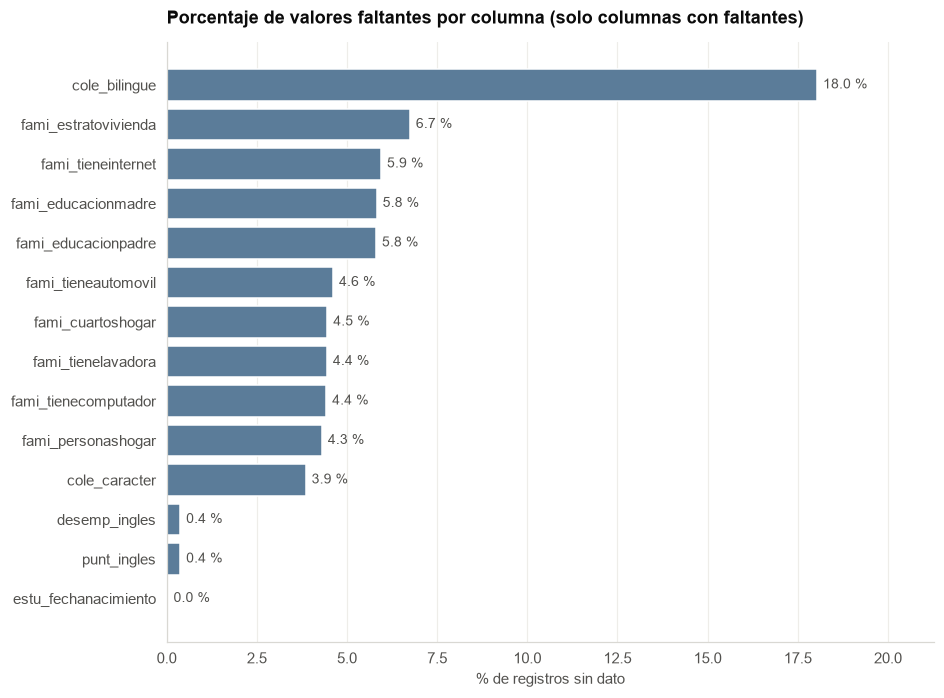

Registros sin ningún dato del cuestionario (fami_* todo nulo): 12,303 (2.31 %)
Registros con al menos un fami_* faltante                   : 54,026 (10.14 %)
Registros con cuestionario completo                          : 478,766 (89.86 %)


,count,mean,std,min,25%,50%,75%,max
sin_cuestionario,"12,303.00",229.10,49.80,0.00,190.00,223.00,264.00,470.00
con_cuestionario,"520,489.00",250.60,51.80,14.00,210.00,247.00,288.00,477.00


In [23]:
faltantes = (df.isna().mean() * 100).round(2)
faltantes = faltantes[faltantes > 0].sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 0.42 * len(faltantes) + 1.2))
bars = ax.barh(faltantes.index, faltantes.values, color=C_NEU)
ax.bar_label(bars, labels=[f"{v:.1f} %" for v in faltantes.values], padding=4, fontsize=9, color=GRIS)
ax.set_title("Porcentaje de valores faltantes por columna (solo columnas con faltantes)")
ax.set_xlabel("% de registros sin dato")
ax.set_xlim(0, faltantes.max() * 1.18)
ax.grid(axis="y", visible=False)
save_fig(fig, "missing_values")
plt.show()

fami_cols = [c for c in df.columns if c.startswith("fami_")]
sin_cuestionario = df[fami_cols].isna().all(axis=1)
algun_faltante = df[fami_cols].isna().any(axis=1)
print(f"Registros sin ningún dato del cuestionario (fami_* todo nulo): {sin_cuestionario.sum():,} "
      f"({sin_cuestionario.mean() * 100:.2f} %)")
print(f"Registros con al menos un fami_* faltante                   : {algun_faltante.sum():,} "
      f"({algun_faltante.mean() * 100:.2f} %)")
print(f"Registros con cuestionario completo                          : {(~algun_faltante).sum():,} "
      f"({(~algun_faltante).mean() * 100:.2f} %)")

comparacion = pd.DataFrame({
    "sin_cuestionario": df.loc[sin_cuestionario, "punt_global"].describe(),
    "con_cuestionario": df.loc[~sin_cuestionario, "punt_global"].describe(),
}).round(1)
display(comparacion.T)

Los datos faltantes se concentran en dos lugares, `cole_bilingue` carece de dato en el 18,0 % de los registros, lo que sugiere que el campo no se reporta para muchos colegios y no que falte al azar, por su parte, en el bloque `fami_*` los porcentajes van del 4,3 % (`fami_personashogar`) al 6,7 % (`fami_estratovivienda`), no obstante, el resto de columnas tiene menos del 4 % y los puntajes están completos salvo inglés (0,37 %).

El cruce entre columnas muestra que el 2,31 % de los estudiantes (12.303) no respondió ninguna pregunta del cuestionario, el 10,14 % tiene al menos una respuesta faltante y el 89,86 % lo diligenció completo. Lo importante es que la ausencia no es aleatoria, quienes no tienen cuestionario obtienen en promedio 229,1 puntos frente a 250,6 de quienes sí lo tienen, 21,5 puntos menos. Eliminar esas filas sesgaría el modelo hacia los estudiantes de mayor puntaje, por eso la decisión para la fase 2 es conservar los faltantes como una categoría explícita (*no respondió*) y agregar un indicador de cuestionario incompleto.

### 4.3 Conversión de tipos y variables derivadas

Dos columnas necesitan transformación antes del análisis:

*   `estu_fechanacimiento` llega como texto `dd/mm/aaaa`, por tanto, se convierte a fecha y se deriva la edad al momento de la prueba (la aplicación del calendario A de 2022 se realizó el 4 de septiembre de 2022). Las edades fuera del rango plausible para un estudiante de grado once (menos de 13 o más de 80 años) se tratan como faltantes y se cuentan.
*   Variables ordinales: `fami_estratovivienda`, `fami_educacionmadre`, `fami_educacionpadre`, `fami_personashogar`, `fami_cuartoshogar` y `desemp_ingles` tienen un orden natural que `category` no conoce fijándose explícitamente para que las tablas y gráficas lo respeten y para la codificación ordinal de la sección 9.

In [24]:
FECHA_PRUEBA = pd.Timestamp("2022-09-04")
fecha_nac = pd.to_datetime(df["estu_fechanacimiento"], format="%d/%m/%Y", errors="coerce")
df["edad"] = ((FECHA_PRUEBA - fecha_nac).dt.days / 365.25).round(1)
fuera_rango = (df["edad"] < 13) | (df["edad"] > 80)
print(f"Fechas no interpretables : {fecha_nac.isna().sum():,}")
print(f"Edades fuera de [13, 80] : {fuera_rango.sum():,} → se marcan como faltantes")
df.loc[fuera_rango, "edad"] = np.nan

ORDEN = {
    "fami_estratovivienda": ["Sin Estrato", "Estrato 1", "Estrato 2", "Estrato 3",
                             "Estrato 4", "Estrato 5", "Estrato 6"],
    "fami_educacionmadre": ["Ninguno", "Primaria incompleta", "Primaria completa",
                            "Secundaria (Bachillerato) incompleta", "Secundaria (Bachillerato) completa",
                            "Técnica o tecnológica incompleta", "Técnica o tecnológica completa",
                            "Educación profesional incompleta", "Educación profesional completa",
                            "Postgrado", "No sabe", "No Aplica"],
    "fami_personashogar": ["1 a 2", "3 a 4", "5 a 6", "7 a 8", "9 o más"],
    "fami_cuartoshogar": ["Uno", "Dos", "Tres", "Cuatro", "Cinco", "Seis o mas"],
    "desemp_ingles": ["A-", "A1", "A2", "B1", "B+"],
}
ORDEN["fami_educacionpadre"] = ORDEN["fami_educacionmadre"]

for col, orden in ORDEN.items():
    presentes = [o for o in orden if o in df[col].cat.categories]
    faltan = [c for c in df[col].cat.categories if c not in orden]
    if faltan:
        print(f"  {col}: categorías no previstas en el orden → {faltan}")
    df[col] = df[col].cat.set_categories(presentes + faltan, ordered=True)

print("\nEdad al presentar la prueba:")
display(df["edad"].describe().round(1).to_frame().T)

Fechas no interpretables : 81
Edades fuera de [13, 80] : 218 → se marcan como faltantes

Edad al presentar la prueba:


,count,mean,std,min,25%,50%,75%,max
edad,"532,493.00",17.80,2.80,13.00,16.70,17.20,18.10,79.80


Solo 81 fechas no pudieron interpretarse y 218 edades quedaron fuera del rango plausible, cifras despreciables sobre 532.792 registros. La edad al presentar la prueba tiene media de 17,8 años y mediana de 17,2 con el 50 % central entre 16,7 y 18,1 años y una cola larga hasta los 79,8 años, que corresponde a adultos que presentan la prueba por jornadas nocturnas, sabatinas o validación y ninguna de las variables ordinales trajo categorías no previstas, de modo que el orden fijado cubre todos los valores del conjunto.

## 5. La variable objetivo: `punt_global`

### 5.1 Distribución

El puntaje global se reporta en una escala de 0 a 500, se examina su distribución con las estadísticas descriptivas, un histograma y un diagrama de caja, para conocer su centro, su dispersión, su simetría y la presencia de valores extremos, que condicionan la elección de la métrica de error y la necesidad de transformar la variable.

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis
punt_global,"532,792.00",250.10,51.80,0.00,210.00,247.00,288.00,477.00,0.28,-0.54


Figura guardada: assets\images\data\target_distribution.png


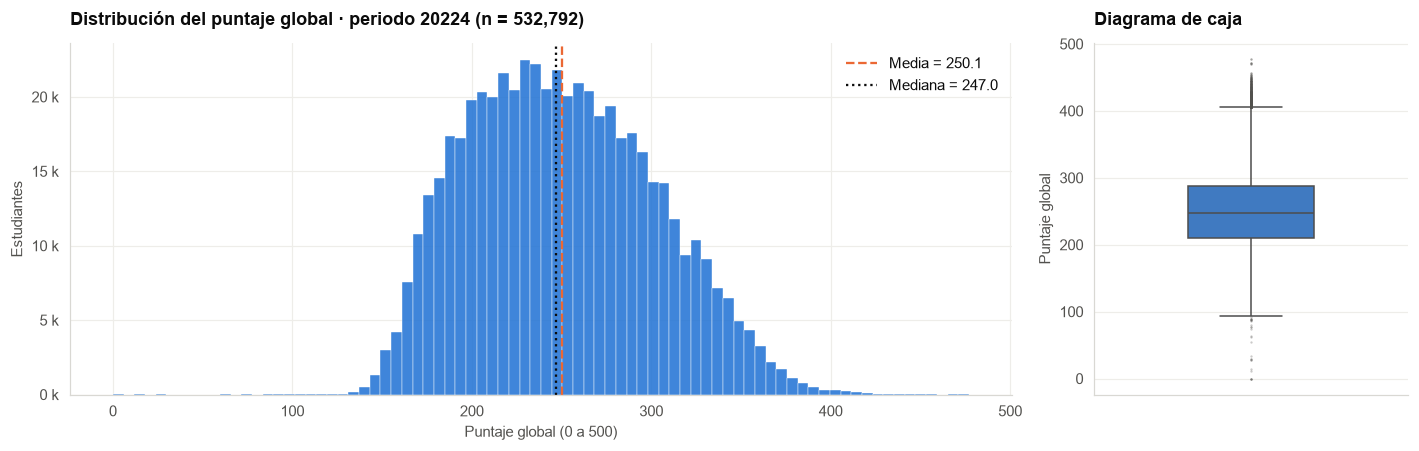

Percentiles 1, 5, 25, 50, 75, 95, 99: [156. 172. 210. 247. 288. 339. 369.]


In [25]:
y = df["punt_global"]
desc = y.describe().round(1)
desc["asimetría"] = round(y.skew(), 3)
desc["curtosis"] = round(y.kurt(), 3)
display(desc.to_frame("punt_global").T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [3, 1]})
axes[0].hist(y.dropna(), bins=80, color=C_BASE, alpha=0.9, edgecolor="white", linewidth=0.3)
axes[0].axvline(y.mean(), color=C_ACCENT, linestyle="--", linewidth=1.5, label=f"Media = {y.mean():.1f}")
axes[0].axvline(y.median(), color=TINTA, linestyle=":", linewidth=1.5, label=f"Mediana = {y.median():.1f}")
axes[0].set_title(f"Distribución del puntaje global · periodo {PERIODO} (n = {y.notna().sum():,})")
axes[0].set_xlabel("Puntaje global (0 a 500)")
axes[0].set_ylabel("Estudiantes")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1000:.0f} k"))
axes[0].legend(frameon=False)

sns.boxplot(y=y, ax=axes[1], color=C_BASE, width=0.4, fliersize=1.5,
            flierprops={"markerfacecolor": GRIS, "markeredgecolor": "none", "alpha": 0.3})
axes[1].set_title("Diagrama de caja")
axes[1].set_ylabel("Puntaje global")
fig.tight_layout()
save_fig(fig, "target_distribution")
plt.show()

p = np.percentile(y.dropna(), [1, 5, 25, 50, 75, 95, 99])
print("Percentiles 1, 5, 25, 50, 75, 95, 99:", np.round(p, 1))

El puntaje global tiene media de 250,1, mediana de 247 y desviación de 51,8 puntos, concluyendo que la moda de los estudiantes queda entre 210 y 288, el 1 % inferior por debajo de 156 y el 1 % superior por encima de 369. La asimetría de 0,28 y la curtosis de −0,54 describen una distribución casi simétrica, con una leve cola derecha y colas más ligeras que la normal, lo que se aprecia en el histograma como una campana apenas desplazada hacia la izquierda de su centro. Para el modelado esto tiene dos consecuencias favorables ya que no hace falta transformar la variable objetivo y las métricas de error (MAE y RMSE) se leen directamente en puntos de la escala. Los pocos valores extremos del diagrama de caja (hasta 477 por arriba y un mínimo de 0) son reales y no se eliminan.

### 5.2 Relación con los puntajes por área (verificación de la fuga de información)

Según la guía de orientación del ICFES, el puntaje global es un promedio ponderado de las cinco pruebas, lectura crítica, matemáticas, sociales y ciudadanas y ciencias naturales pesan 3 cada una e inglés pesa 1 y el resultado se escala a 500 puntos:

$$
\text{punt\_global} = \text{round}\left( \frac{3\,LC + 3\,MAT + 3\,SOC + 3\,CN + 1\,ING}{13} \times 5 \right)
$$

Se verifica esa fórmula sobre los datos y se calcula la correlación de cada área con el puntaje global, si la ecuación se cumple, los puntajes por área no son variables explicativas sino componentes de la respuesta y deben excluirse del modelo.

In [26]:
calc = ((3 * df["punt_lectura_critica"] + 3 * df["punt_matematicas"] + 3 * df["punt_sociales_ciudadanas"]
         + 3 * df["punt_c_naturales"] + 1 * df["punt_ingles"]) / 13 * 5)
diff = (df["punt_global"] - calc.round()).abs()
completos = calc.notna()
print(f"Registros con las cinco pruebas    : {completos.sum():,} de {len(df):,}")
print(f"Coinciden exactamente con la fórmula: {(diff[completos] == 0).mean() * 100:.2f} %")
print(f"Diferencia absoluta máxima          : {diff[completos].max():.0f} puntos")
print(f"Diferencia absoluta ≤ 1 punto       : {(diff[completos] <= 1).mean() * 100:.2f} %")

corr_areas = df[SCORE_COLS].corr(method="pearson")["punt_global"].drop("punt_global").sort_values(ascending=False)
display(corr_areas.round(3).to_frame("correlación de Pearson con punt_global").T)

Registros con las cinco pruebas    : 530,815 de 532,792
Coinciden exactamente con la fórmula: 100.00 %
Diferencia absoluta máxima          : 0 puntos
Diferencia absoluta ≤ 1 punto       : 100.00 %


,punt_c_naturales,punt_sociales_ciudadanas,punt_lectura_critica,punt_matematicas,punt_ingles
correlación de Pearson con punt_global,0.92,0.92,0.91,0.91,0.80


La fórmula se cumple en el 100 % de los 530.815 registros que tienen las cinco pruebas, con una diferencia máxima de 0 puntos, el puntaje global es exactamente el promedio ponderado de las áreas redondeado al entero. Cada área tiene una correlación de Pearson de 0,91 a 0,92 con el global e inglés de 0,80 (pesa 1 de 13 en lugar de 3). Esto confirma la restricción del planteamiento, cualquier modelo que incluya los puntajes por área o el nivel de inglés obtendría un error casi nulo sin haber aprendido nada sobre el estudiante, porque estaría reconstruyendo la respuesta a partir de sus componentes. Las seis columnas de resultados por área quedan excluidas del conjunto de variables explicativas y solo se conservan en este cuaderno para documentar el contraste en la matriz de correlación.

## 6. Variables del estudiante

Se analiza la relación del puntaje global con el género, la edad y el tipo de documento del estudiante. Para cada variable se reporta el tamaño del grupo, la media, la mediana y la desviación del puntaje y se grafica con diagramas de caja sin valores atípicos evitando que la comparación entre grupos quede dominada por los extremos. La edad se agrupa en tramos porque la relación con el puntaje no tiene por qué ser lineal, puesto que los estudiantes mucho mayores que la edad típica de grado once suelen provenir de jornadas nocturnas o de validación.

Figura guardada: assets\images\data\student_variables.png


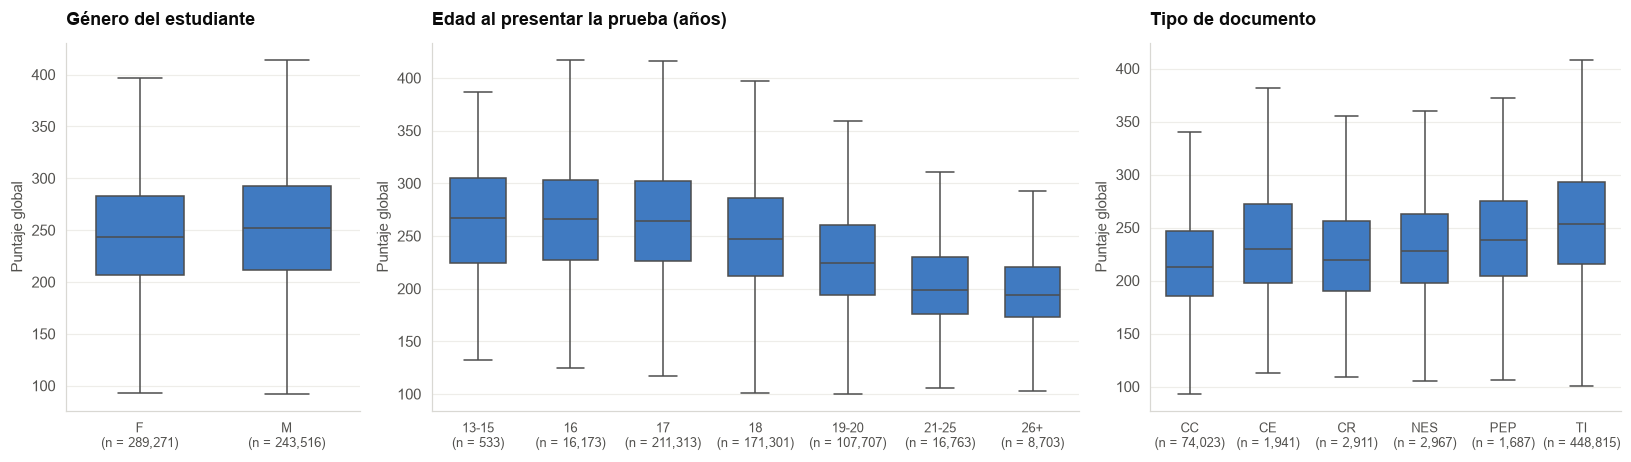

Género:


estu_genero,F,M
n,"289,271.00","243,516.00"
media,246.80,254.10
mediana,243.00,252.00
desv,50.50,53.20


Edad:


edad_grupo,13-15,16,17,18,19-20,21-25,26+
n,533.00,"16,173.00","211,313.00","171,301.00","107,707.00","16,763.00","8,703.00"
media,264.00,265.40,264.80,250.50,229.50,206.10,199.60
mediana,267.00,266.00,264.00,247.00,224.00,199.00,194.00
desv,55.40,51.20,50.80,50.30,45.40,39.30,36.10


Tipo de documento (grupos con n ≥ 1.000):


estu_tipodocumento,CC,CE,CR,NES,PEP,TI
n,"74,023.00","1,941.00","2,911.00","2,967.00","1,687.00","448,815.00"
media,219.40,238.60,226.10,232.90,241.70,255.60
mediana,213.00,230.00,219.00,228.00,238.00,253.00
desv,43.90,50.80,45.40,44.10,47.80,51.30


In [27]:
def resumen_por(col, orden=None, min_n=0):
    """Tamaño, media, mediana y desviación del puntaje global por categoría de `col`."""
    tabla = (df.groupby(col, observed=True)["punt_global"]
               .agg(n="size", media="mean", mediana="median", desv="std").round(1))
    if orden is not None:
        tabla = tabla.reindex([o for o in orden if o in tabla.index])
    return tabla[tabla["n"] >= min_n]

def caja_por(ax, col, orden=None, titulo=None, color=C_BASE, rot=0, min_n=0):
    """Diagrama de caja del puntaje global por categoría, con el tamaño de cada grupo en el eje."""
    tabla = resumen_por(col, orden, min_n)
    sns.boxplot(data=df[df[col].isin(tabla.index)], x=col, y="punt_global", order=tabla.index,
                ax=ax, color=color, width=0.6, showfliers=False)
    ax.set_xticklabels([f"{c}\n(n = {n:,})" for c, n in zip(tabla.index, tabla["n"])], rotation=rot,
                       ha="right" if rot else "center", fontsize=8.5)
    ax.set_title(titulo or col)
    ax.set_xlabel("")
    ax.set_ylabel("Puntaje global")
    return tabla

df["edad_grupo"] = pd.cut(df["edad"], bins=[12, 15, 16, 17, 18, 20, 25, 80],
                          labels=["13-15", "16", "17", "18", "19-20", "21-25", "26+"], right=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1, 2.2, 1.6]})
t_genero = caja_por(axes[0], "estu_genero", ["F", "M"], "Género del estudiante")
t_edad = caja_por(axes[1], "edad_grupo", None, "Edad al presentar la prueba (años)")
t_doc = caja_por(axes[2], "estu_tipodocumento", None, "Tipo de documento", min_n=1000)
fig.tight_layout()
save_fig(fig, "student_variables")
plt.show()

print("Género:"); display(t_genero.T)
print("Edad:"); display(t_edad.T)
print("Tipo de documento (grupos con n ≥ 1.000):"); display(t_doc.T)

Tres patrones emergen de las variables del estudiante:

*   **Género:** los hombres obtienen en promedio 254,1 puntos y las mujeres 246,8, una brecha de 7,3 puntos con medianas de 252 y 243, siendo una diferencia conocida en la prueba, pequeña frente a la dispersión (desviación de 50 a 53 puntos) pero sistemática.
*   **Edad:** es una de las variables más informativas, los estudiantes de 16 y 17 años, la edad típica de grado once, promedian 265 puntos, a los 18 el promedio baja a 250,5, a los 19 y 20 a 229,5, entre 21 y 25 a 206,1 y de 26 en adelante a 199,6. La relación es monótona decreciente y la caída entre los 17 y los 26 años supera los 65 punto, por ende, la edad no actúa por sí misma, sino como marcador de trayectorias de extraedad, repitencia y educación de adultos (jornadas nocturna y sabatina).
*   **Tipo de documento:** la tarjeta de identidad (menores, 448.815 estudiantes) promedia 255,6 y la cédula de ciudadanía (74.023 adultos) 219,4. Las cédulas de extranjería y los permisos especiales de permanencia, en su mayoría población migrante, promedian entre 238 y 242 con grupos de menos de 3.000 estudiantes.

## 7. Variables del hogar

El bloque `fami_*` describe el entorno socioeconómico del estudiante, analizado en dos frentes:

*   **Variables ordinales**: estrato de la vivienda y máximo nivel educativo de la madre y del padre, si la hipótesis H1 es correcta, la mediana del puntaje debería crecer de manera monótona con cada nivel.
*   **Variables binarias y de composición del hogar**: tenencia de internet, computador, automóvil y lavadora y número de personas y cuartos del hogar, las cuales compara la media del puntaje entre quienes tienen y no tienen cada bien, con la diferencia en puntos.

Figura guardada: assets\images\data\family_ordinal.png


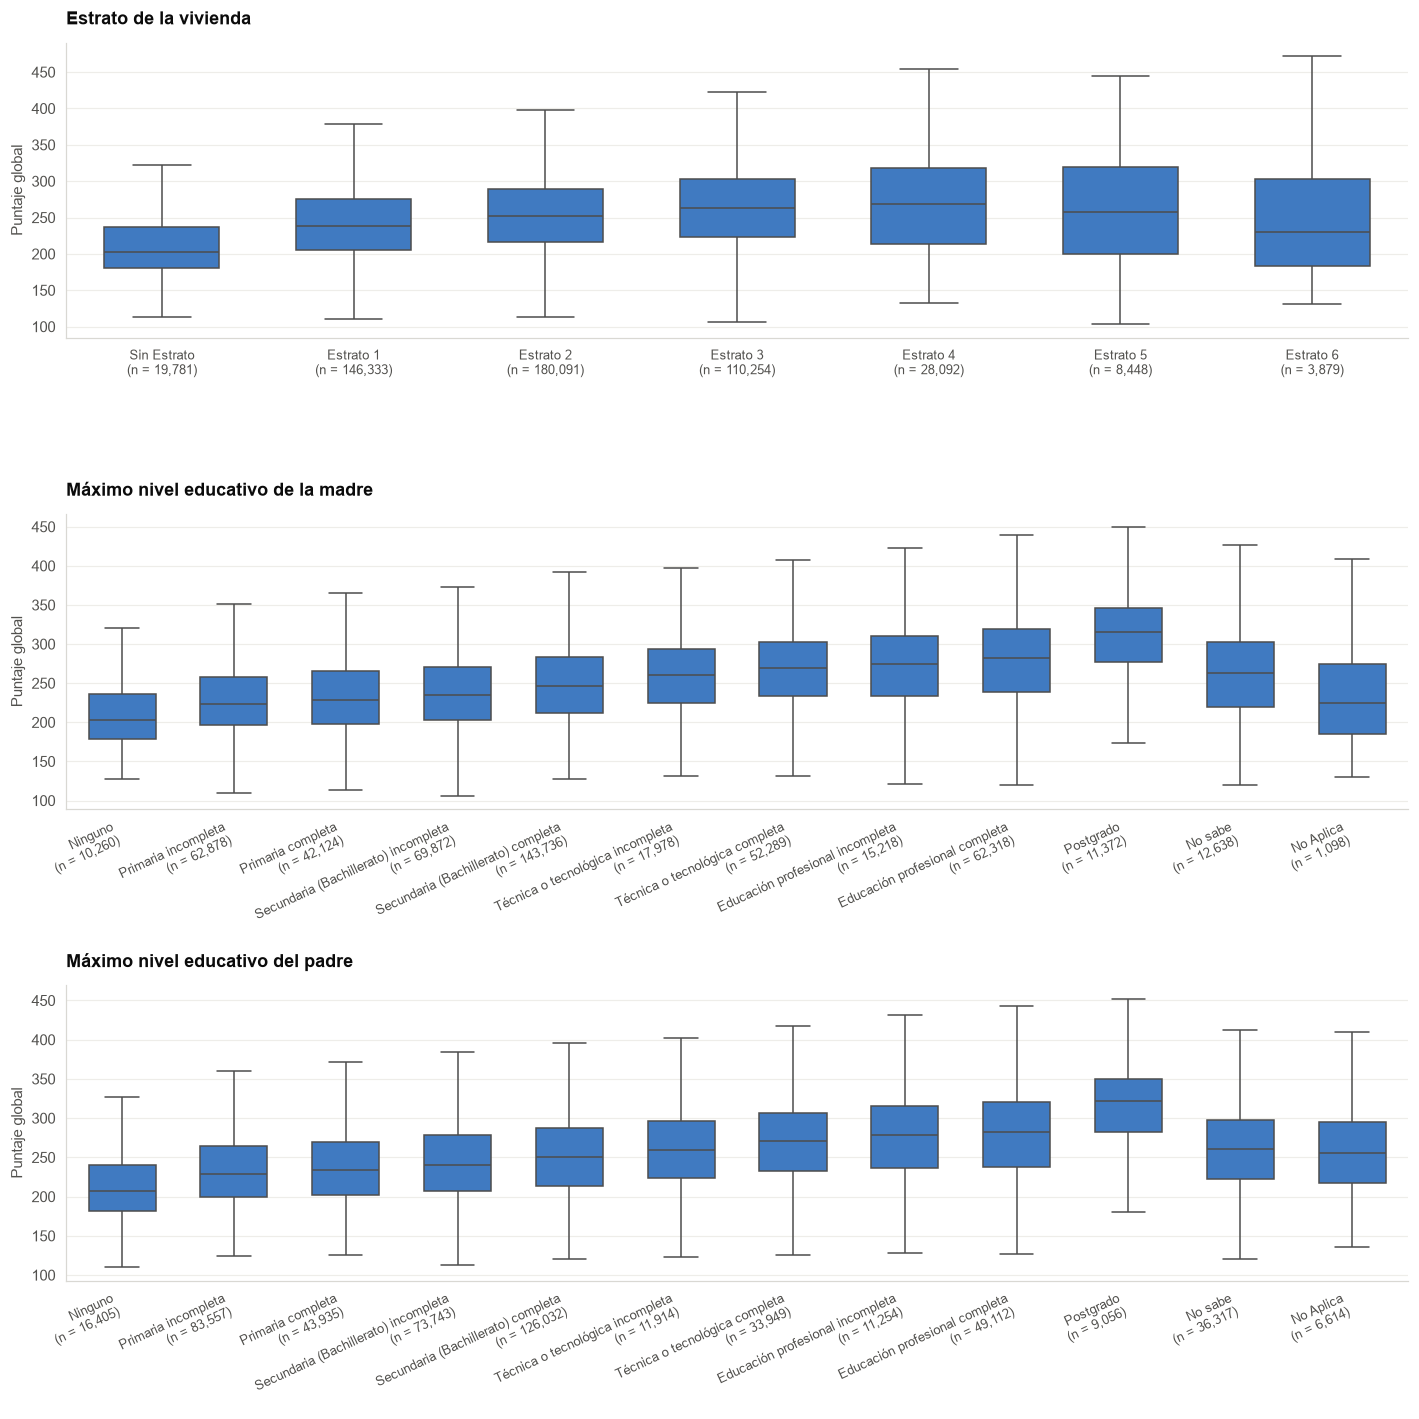

Estrato:


fami_estratovivienda,Sin Estrato,Estrato 1,Estrato 2,Estrato 3,Estrato 4,Estrato 5,Estrato 6
n,"19,781.00","146,333.00","180,091.00","110,254.00","28,092.00","8,448.00","3,879.00"
media,212.60,242.00,253.70,263.20,267.40,261.40,245.10
mediana,203.00,238.00,252.00,263.00,269.00,258.00,230.00
desv,43.40,47.00,48.80,52.60,62.40,67.30,69.50


Educación de la madre:


fami_educacionmadre,Ninguno,Primaria incompleta,Primaria completa,Secundaria (Bachillerato) incompleta,Secundaria (Bachillerato) completa,Técnica o tecnológica incompleta,Técnica o tecnológica completa,Educación profesional incompleta,Educación profesional completa,Postgrado,No sabe,No Aplica
n,"10,260.00","62,878.00","42,124.00","69,872.00","143,736.00","17,978.00","52,289.00","15,218.00","62,318.00","11,372.00","12,638.00","1,098.00"
media,211.20,228.80,233.40,238.80,249.40,259.90,268.00,271.70,278.40,307.50,261.50,233.50
mediana,203.00,224.00,229.00,235.00,247.00,260.00,269.00,274.00,282.00,316.00,263.00,225.00
desv,41.50,43.10,45.50,45.60,48.30,47.50,48.30,51.50,54.00,54.10,55.10,57.20


Educación del padre:


fami_educacionpadre,Ninguno,Primaria incompleta,Primaria completa,Secundaria (Bachillerato) incompleta,Secundaria (Bachillerato) completa,Técnica o tecnológica incompleta,Técnica o tecnológica completa,Educación profesional incompleta,Educación profesional completa,Postgrado,No sabe,No Aplica
n,"16,405.00","83,557.00","43,935.00","73,743.00","126,032.00","11,914.00","33,949.00","11,254.00","49,112.00","9,056.00","36,317.00","6,614.00"
media,214.50,233.80,237.90,243.50,251.40,260.10,269.80,274.40,278.20,311.90,260.70,256.50
mediana,207.00,229.00,234.00,240.00,250.00,260.00,271.00,278.00,282.00,322.00,261.00,255.00
desv,42.60,44.40,46.60,47.50,49.00,49.30,49.70,53.40,55.10,54.50,50.80,51.60


In [28]:
fig, axes = plt.subplots(3, 1, figsize=(13, 13))
t_estrato = caja_por(axes[0], "fami_estratovivienda", ORDEN["fami_estratovivienda"], "Estrato de la vivienda")
t_madre = caja_por(axes[1], "fami_educacionmadre", ORDEN["fami_educacionmadre"],
                   "Máximo nivel educativo de la madre", rot=25)
t_padre = caja_por(axes[2], "fami_educacionpadre", ORDEN["fami_educacionpadre"],
                   "Máximo nivel educativo del padre", rot=25)
fig.tight_layout()
save_fig(fig, "family_ordinal")
plt.show()

print("Estrato:"); display(t_estrato.T)
print("Educación de la madre:"); display(t_madre.T)
print("Educación del padre:"); display(t_padre.T)

Las tres variables ordinales del hogar muestran la gradiente socioeconómica que plantea la hipótesis H1, con un matiz importante en el estrato:

*   **Estrato:** el puntaje medio sube de forma monótona desde *Sin estrato* (212,6) y estrato 1 (242,0) hasta el estrato 4 (267,4), pero cae en los estratos 5 (261,4) y 6 (245,1), que además tienen las desviaciones más altas (67 y 70 puntos) y los grupos más pequeños (8.448 y 3.879 estudiantes). Ese quiebre es inesperado y contradice la lógica de la variable y la explicación más probable es error de reporte en el cuestionario (el estudiante declara un estrato que no corresponde a su vivienda), lo que hace del estrato una variable menos confiable de lo que su definición sugiere.
*   **Educación de la madre:** la relación es perfectamente monótona de 211,2 puntos cuando la madre no tiene ningún nivel educativo a 307,5 cuando tiene posgrado, 96 puntos de diferencia, el contraste más amplio de todo el análisis exploratorio, ya que cada grado de escolaridad (primaria, secundaria, técnica, profesional, posgrado) añade entre 5 y 30 puntos. La categoría *No sabe* (12.638 estudiantes) promedia 261,5, por encima de la media, y *No Aplica* (1.098) 233,5.
*   **Educación del padre:** el mismo patrón se da, de 214,5 a 311,9 puntos, con una particularidad, *No sabe* reúne 36.317 estudiantes (6,8 %) casi el triple que en la madre, lo que refleja hogares sin presencia paterna promedian 260,7, por lo que la categoría no debe tratarse como faltante sino como un nivel propio.

,n_si,n_no,media_si,media_no,diferencia
variable,,,,,
tiene_internet,363808,137328,260.20,228.40,31.80
tiene_computador,271666,237559,265.50,233.80,31.70
tiene_automovil,128811,379398,268.40,244.80,23.60
tiene_lavadora,394207,114946,255.40,234.60,20.80


Figura guardada: assets\images\data\family_binary.png


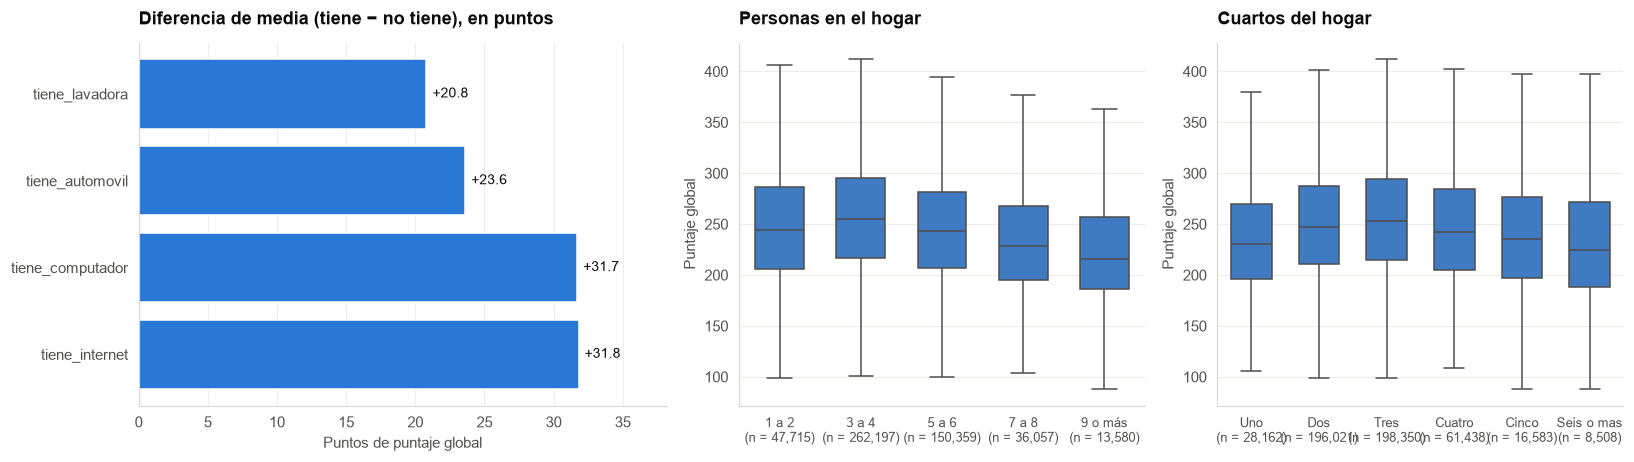

Personas en el hogar:


fami_personashogar,1 a 2,3 a 4,5 a 6,7 a 8,9 o más
n,"47,715.00","262,197.00","150,359.00","36,057.00","13,580.00"
media,247.60,257.10,246.50,234.00,225.00
mediana,244.00,255.00,243.00,228.00,216.00
desv,52.70,51.70,50.30,48.90,49.20


Cuartos del hogar:


fami_cuartoshogar,Uno,Dos,Tres,Cuatro,Cinco,Seis o mas
n,"28,162.00","196,021.00","198,350.00","61,438.00","16,583.00","8,508.00"
media,235.80,250.60,255.80,246.60,239.50,232.30
mediana,230.00,247.00,253.00,242.00,235.00,225.00
desv,49.70,50.60,52.10,52.20,52.10,53.00


In [29]:
BIENES = ["fami_tieneinternet", "fami_tienecomputador", "fami_tieneautomovil", "fami_tienelavadora"]
filas = []
for col in BIENES:
    g = df.groupby(col, observed=True)["punt_global"].agg(["size", "mean"])
    filas.append({"variable": col.replace("fami_tiene", "tiene_"),
                  "n_si": int(g.loc["Si", "size"]), "n_no": int(g.loc["No", "size"]),
                  "media_si": round(g.loc["Si", "mean"], 1), "media_no": round(g.loc["No", "mean"], 1),
                  "diferencia": round(g.loc["Si", "mean"] - g.loc["No", "mean"], 1)})
bienes = pd.DataFrame(filas).set_index("variable").sort_values("diferencia", ascending=False)
display(bienes)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.3, 1, 1]})
bars = axes[0].barh(bienes.index, bienes["diferencia"], color=C_BASE)
axes[0].bar_label(bars, labels=[f"+{v:.1f}" for v in bienes["diferencia"]], padding=4, fontsize=9)
axes[0].set_title("Diferencia de media (tiene − no tiene), en puntos")
axes[0].set_xlabel("Puntos de puntaje global")
axes[0].set_xlim(0, bienes["diferencia"].max() * 1.2)
axes[0].grid(axis="y", visible=False)
t_personas = caja_por(axes[1], "fami_personashogar", ORDEN["fami_personashogar"], "Personas en el hogar")
t_cuartos = caja_por(axes[2], "fami_cuartoshogar", ORDEN["fami_cuartoshogar"], "Cuartos del hogar")
fig.tight_layout()
save_fig(fig, "family_binary")
plt.show()

print("Personas en el hogar:"); display(t_personas.T)
print("Cuartos del hogar:"); display(t_cuartos.T)

Los cuatro bienes del hogar se asocian con un puntaje mayor, pero no por igual, ya que tener internet (+31,8 puntos) y computador (+31,7) marcan una diferencia muy superior a la del automóvil (+23,6) y la lavadora (+20,8). Los dos primeros son indicadores de ingreso y herramientas directamente ligadas al estudio, lo que explica que destaquen sobre bienes puramente patrimoniales. En 2022 todavía el 27 % de los hogares (137.328) declaraba no tener internet.

La composición del hogar no es monótona ya que el puntaje es máximo en hogares de 3 a 4 personas (257,1) y desciende tanto hacia hogares de 1 a 2 personas (247,6) como, sobre todo, hacia los de 9 o más (225,0). Con los cuartos ocurre lo mismo, el máximo está en tres cuartos (255,8) y cae en ambos extremos, un cuarto con 235,8 y seis o más con 232,3, porque las viviendas con muchos cuartos son frecuentes en zonas rurales de bajo ingreso. Ninguna de las dos variables debe entrar al modelo como un simple número, ya que la razón personas por cuarto (una medida de hacinamiento) es una variable derivada natural para la fase 2.

## 8. Variables del colegio

Las variables `cole_*` describen la institución donde el estudiante cursó la media. Se comparan el puntaje global según la naturaleza (oficial o no oficial), el área (urbana o rural), la jornada, el calendario, el carácter (académico, técnico o ambos), si es bilingüe y el género de la población que atiende y son las variables que ponen a prueba la hipótesis H2. Las categorías con menos de 1.000 estudiantes se omiten de las gráficas pero se cuentan en las tablas.

Figura guardada: assets\images\data\school_variables.png


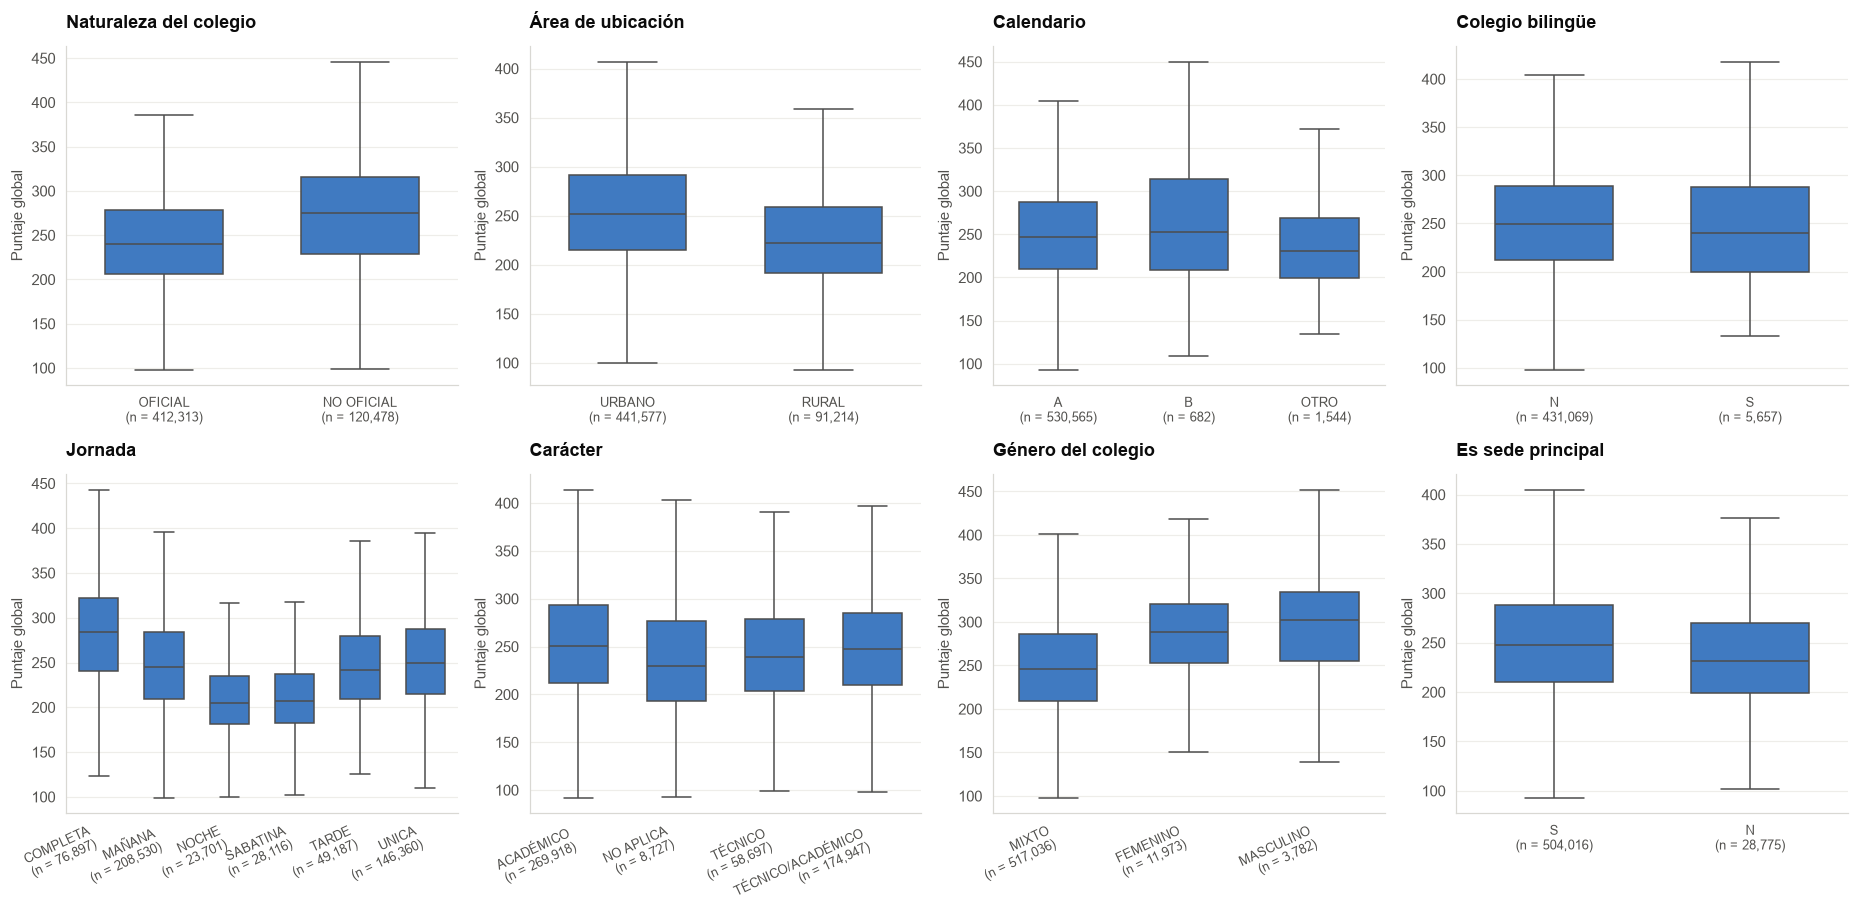

Naturaleza:


cole_naturaleza,OFICIAL,NO OFICIAL
n,"412,313.00","120,478.00"
media,243.60,272.60
mediana,240.00,275.00
desv,48.40,56.60


Área:


cole_area_ubicacion,URBANO,RURAL
n,"441,577.00","91,214.00"
media,254.60,228.40
mediana,252.00,222.00
desv,51.60,47.40


Calendario:


...

cole_jornada,COMPLETA,MAÑANA,NOCHE,SABATINA,TARDE,UNICA
n,"76,897.00","208,530.00","23,701.00","28,116.00","49,187.00","146,360.00"
media,280.80,248.20,210.60,212.70,245.50,252.00
mediana,284.00,245.00,205.00,207.00,242.00,250.00
desv,54.10,50.40,39.20,39.20,47.60,47.90


Carácter:


cole_caracter,ACADÉMICO,NO APLICA,TÉCNICO,TÉCNICO/ACADÉMICO
n,"269,918.00","8,727.00","58,697.00","174,947.00"
media,253.90,237.00,243.30,248.90
mediana,251.00,230.00,239.00,247.00
desv,53.40,53.70,49.60,49.40


Género del colegio:


cole_genero,MIXTO,FEMENINO,MASCULINO
n,"517,036.00","11,973.00","3,782.00"
media,249.00,285.50,294.20
mediana,246.00,289.00,302.00
desv,51.50,48.00,55.60


In [30]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8.5))
axes = axes.ravel()
t_nat = caja_por(axes[0], "cole_naturaleza", ["OFICIAL", "NO OFICIAL"], "Naturaleza del colegio")
t_area = caja_por(axes[1], "cole_area_ubicacion", ["URBANO", "RURAL"], "Área de ubicación")
t_cal = caja_por(axes[2], "cole_calendario", ["A", "B", "OTRO"], "Calendario")
t_bil = caja_por(axes[3], "cole_bilingue", ["N", "S"], "Colegio bilingüe")
t_jor = caja_por(axes[4], "cole_jornada", None, "Jornada", rot=25, min_n=1000)
t_car = caja_por(axes[5], "cole_caracter", None, "Carácter", rot=25, min_n=1000)
t_gen = caja_por(axes[6], "cole_genero", ["MIXTO", "FEMENINO", "MASCULINO"], "Género del colegio", rot=25)
t_sede = caja_por(axes[7], "cole_sede_principal", ["S", "N"], "Es sede principal")
fig.tight_layout()
save_fig(fig, "school_variables")
plt.show()

for nombre, tabla in [("Naturaleza", t_nat), ("Área", t_area), ("Calendario", t_cal), ("Bilingüe", t_bil),
                      ("Jornada", t_jor), ("Carácter", t_car), ("Género del colegio", t_gen)]:
    print(f"{nombre}:"); display(tabla.T)

Las variables del colegio respaldan la hipótesis H2 y aportan la brecha más amplia después de la educación de los padres:

*   **Naturaleza:** los colegios no oficiales promedian 272,6 puntos frente a 243,6 de los oficiales, 29 puntos de diferencia, los oficiales concentran el 77 % de los estudiantes (412.313).
*   **Área:** los colegios urbanos promedian 254,6 y los rurales 228,4, 26,2 puntos menos, el 17 % de los estudiantes (91.214) estudia en zona rural.
*   **Jornada:** es la variable del colegio con mayor rango, la jornada **completa promedia 280,8** y la única 252,0, mientras que la sabatina (212,7) y la nocturna (210,6) quedan 70 puntos por debajo de la completa. Las jornadas nocturna y sabatina reúnen 51.817 estudiantes, en su mayoría adultos.
*   **Carácter:** académico (253,9) supera a técnico/académico (248,9) y a técnico (243,3), con *No aplica* (237,0) al final, todo esto se resume en que las diferencias son moderadas.
*   **Bilingüe:** los colegios marcados como bilingües promedian 247,0, por debajo de los no bilingües (252,1), sumado a su 18 % de faltantes, el indicador parece poco confiable y de escaso valor predictivo.
*   **Calendario y género del colegio:** los colegios de calendario B (682 estudiantes en este periodo) promedian 263,3, los colegios femeninos 285,5 y masculinos 294,2, superando por mucho a los mixtos con 249,0, pero son grupos pequeños (11.973 y 3.782) compuestos sobre todo por colegios privados, de modo que el efecto es en gran parte el de la naturaleza.

Naturaleza y área se cruzan a menudo, la mayoría de colegios rurales son oficiales y para separar ambos efectos se tabula el puntaje medio en las cuatro combinaciones, junto con la cantidad de estudiantes de cada una.

In [31]:
cruce = df.pivot_table(index="cole_naturaleza", columns="cole_area_ubicacion", values="punt_global",
                       aggfunc=["mean", "size"], observed=True)
cruce.columns = [f"{a}_{b}" for a, b in cruce.columns]
display(cruce.round(1))

,mean_RURAL,mean_URBANO,size_RURAL,size_URBANO
cole_naturaleza,,,,
NO OFICIAL,291.10,271.70,5328,115150
OFICIAL,224.50,248.60,85886,326427


Entre los colegios oficiales, la brecha urbano-rural es de 24 puntos (248,6 frente a 224,5), pero entre los no oficiales se invierte, los privados rurales promedian 291,1, el valor más alto de las cuatro celdas, porque son pocos (5.328 estudiantes) y corresponden en buena parte a instituciones campestres de alto costo en las afueras de las ciudades. El orden completo es, privado rural (291,1) > privado urbano (271,7) > oficial urbano (248,6) > oficial rural (224,5). Para un modelo lineal esto exige un término de interacción entre naturaleza y área, un modelo de árboles lo captura por sí solo.

## 9. Variables geográficas

El departamento donde se ubica el colegio resume condiciones que las variables anteriores no capturan del todo, oferta educativa, ruralidad, conflicto, inversión pública y se calcula el puntaje medio y la cantidad de estudiantes por departamento, se ordena y se grafica, para evaluar la hipótesis H3 y decidir cómo codificar esta variable de 33 niveles en la fase 2.

cole_depto_ubicacion,BOGOTÁ,BOYACA,SANTANDER,CUNDINAMARCA,QUINDIO,NORTE SANTANDER,RISARALDA,HUILA,CASANARE,CALDAS,META,NARIÑO,VALLE,ANTIOQUIA,ATLANTICO,TOLIMA,CESAR,CAQUETA,ARAUCA,PUTUMAYO,CORDOBA,SAN ANDRES,SUCRE,CAUCA,BOLIVAR,GUAVIARE,MAGDALENA,GUAINIA,LA GUAJIRA,VICHADA,AMAZONAS,VAUPES,CHOCO
n,"76,253.00","15,072.00","24,884.00","35,021.00","5,655.00","16,316.00","9,670.00","13,180.00","5,529.00","9,932.00","11,732.00","16,465.00","39,360.00","72,383.00","31,160.00","15,711.00","13,575.00","3,940.00","3,316.00","3,880.00","22,281.00",577.00,"11,203.00","13,722.00","27,212.00","1,049.00","16,865.00",389.00,"9,775.00",609.00,823.00,434.00,"4,818.00"
media,270.20,268.60,267.00,262.80,260.80,259.70,255.00,254.90,253.60,253.10,252.90,248.10,247.90,245.90,245.20,244.60,242.40,241.70,241.50,239.70,238.30,237.40,236.60,231.10,230.00,228.80,227.50,224.20,221.50,217.90,215.50,213.70,206.10
mediana,270.00,269.00,266.00,262.00,259.00,258.00,253.00,252.00,250.00,249.00,250.00,247.00,245.00,242.00,240.00,240.00,237.00,237.00,238.00,236.00,231.00,232.00,228.00,224.00,220.00,223.00,220.00,214.00,213.00,212.00,208.00,206.50,197.00
desv,48.70,48.20,52.50,47.50,53.30,51.30,50.20,51.10,48.30,49.90,48.50,52.60,49.10,51.60,52.80,49.30,50.00,48.20,46.40,45.40,49.60,52.40,51.10,47.70,50.90,44.90,47.20,48.70,48.10,43.50,42.50,41.80,41.50


Figura guardada: assets\images\data\geography.png


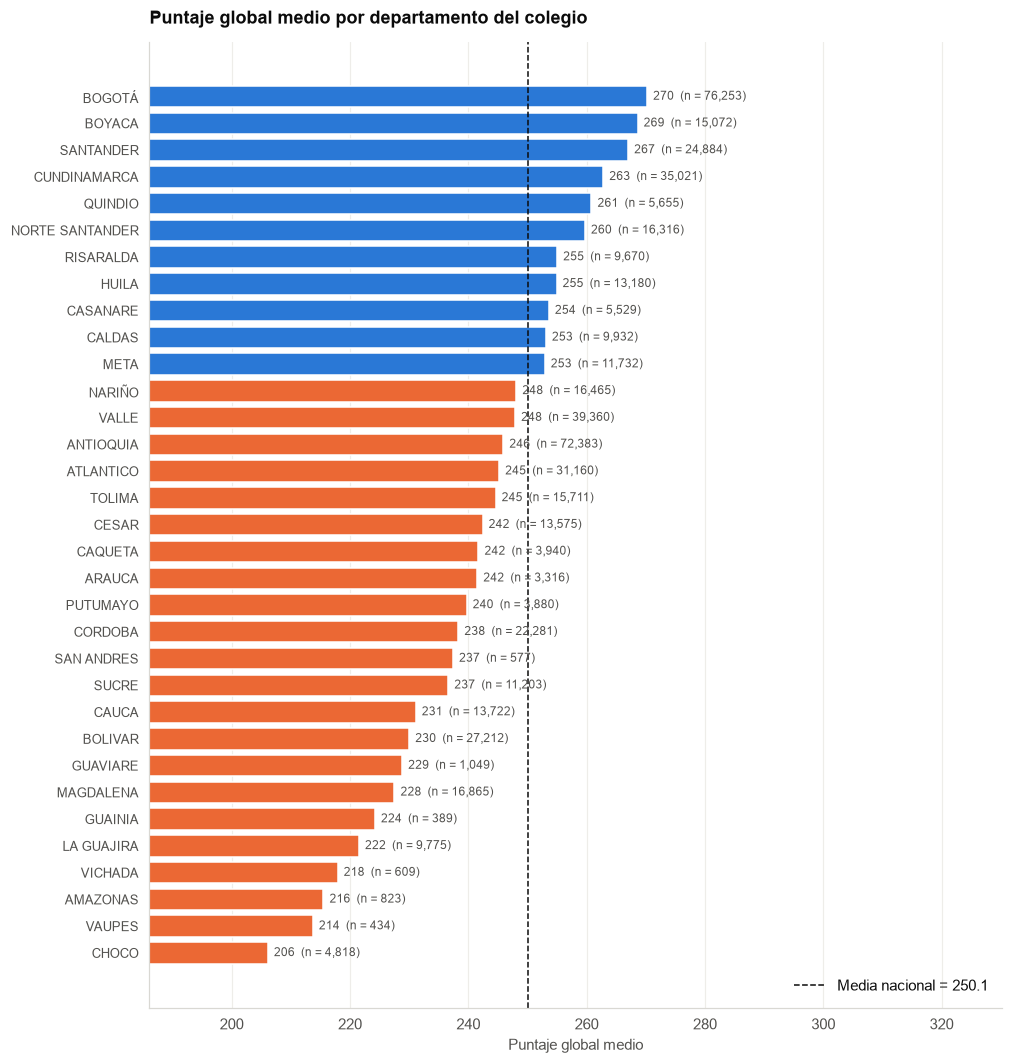

Brecha entre el departamento con mayor y menor media: 64.1 puntos (BOGOTÁ vs. CHOCO)


In [32]:
geo = (df.groupby("cole_depto_ubicacion", observed=True)["punt_global"]
         .agg(n="size", media="mean", mediana="median", desv="std").round(1)
         .sort_values("media", ascending=True))
display(geo.sort_values("media", ascending=False).T)

fig, ax = plt.subplots(figsize=(10, 0.3 * len(geo) + 1.5))
colores = [C_ACCENT if m < df["punt_global"].mean() else C_BASE for m in geo["media"]]
bars = ax.barh(geo.index, geo["media"], color=colores)
ax.bar_label(bars, labels=[f"{m:.0f}  (n = {n:,})" for m, n in zip(geo["media"], geo["n"])],
             padding=4, fontsize=8, color=GRIS)
ax.axvline(df["punt_global"].mean(), color=TINTA, linestyle="--", linewidth=1,
           label=f"Media nacional = {df['punt_global'].mean():.1f}")
ax.set_xlim(geo["media"].min() - 20, geo["media"].max() + 60)
ax.set_title("Puntaje global medio por departamento del colegio")
ax.set_xlabel("Puntaje global medio")
ax.tick_params(axis="y", labelsize=8.5)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
save_fig(fig, "geography")
plt.show()

print(f"Brecha entre el departamento con mayor y menor media: "
      f"{geo['media'].max() - geo['media'].min():.1f} puntos "
      f"({geo['media'].idxmax()} vs. {geo['media'].idxmin()})")

La brecha regional es grande y ordenada, Bogotá (270,2), Boyacá (268,6), Santander (267,0) y Cundinamarca (262,8) encabezan la lista y Chocó (206,1), Vaupés (213,7), Amazonas (215,5), Vichada (217,9) y La Guajira (221,5) la cierran. Entre el primero y el último hay 64,1 puntos, más que la diferencia entre colegios oficiales y privados. Solo 11 de los 33 departamentos superan la media nacional de 250,1 y el mapa de colores dibuja el centro andino por encima y la periferia pacífica, amazónica y caribe por debajo, en línea con la hipótesis H3.

La variable tiene dos retos para el modelado, primero, la geografía está correlacionada con las variables del hogar y del colegio (los departamentos de menor puntaje son también los de mayor ruralidad y menor acceso a internet), así que parte del efecto se repartirá con ellas, segundo, varios departamentos tienen muy pocos estudiantes (Guainía 389, Vaupés 434, San Andrés 577), por lo que una codificación *one-hot* es viable pero una codificación por objetivo con suavizado o una agrupación por región será más estable, sin embargo, el municipio con más de 1.000 niveles solo admite la segunda opción.

## 10. Correlaciones

Para medir conjuntamente la asociación de todas las variables candidatas con el puntaje global, las variables ordinales se codifican con enteros que respetan su orden (estrato 0 a 6, nivel educativo 0 a 9, personas y cuartos por tramo), las binarias con 0 y 1 y se calcula la correlación de Spearman, apropiada para variables ordinales y robusta a la no linealidad. Las categorías *No sabe* y *No Aplica* de educación de los padres se tratan como faltantes en esta codificación. La matriz incluye también los puntajes por área, para que quede documentado el contraste entre una variable explicativa legítima y una que forma parte de la respuesta.

Correlación de Spearman con punt_global (ordenada por magnitud):


,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_matematicas,punt_ingles,educ_madre,edad,educ_padre,tiene_computador,tiene_internet,colegio_no_oficial,estrato,colegio_urbano,jornada_completa_unica,tiene_automovil,tiene_lavadora,personas_hogar,genero_F,colegio_bilingue,cuartos_hogar,calendario_B
rho,0.92,0.92,0.92,0.91,0.79,0.35,-0.32,0.32,0.30,0.28,0.22,0.19,0.19,0.19,0.19,0.17,-0.11,-0.07,-0.01,0.01,0.01


Figura guardada: assets\images\data\correlation_matrix.png


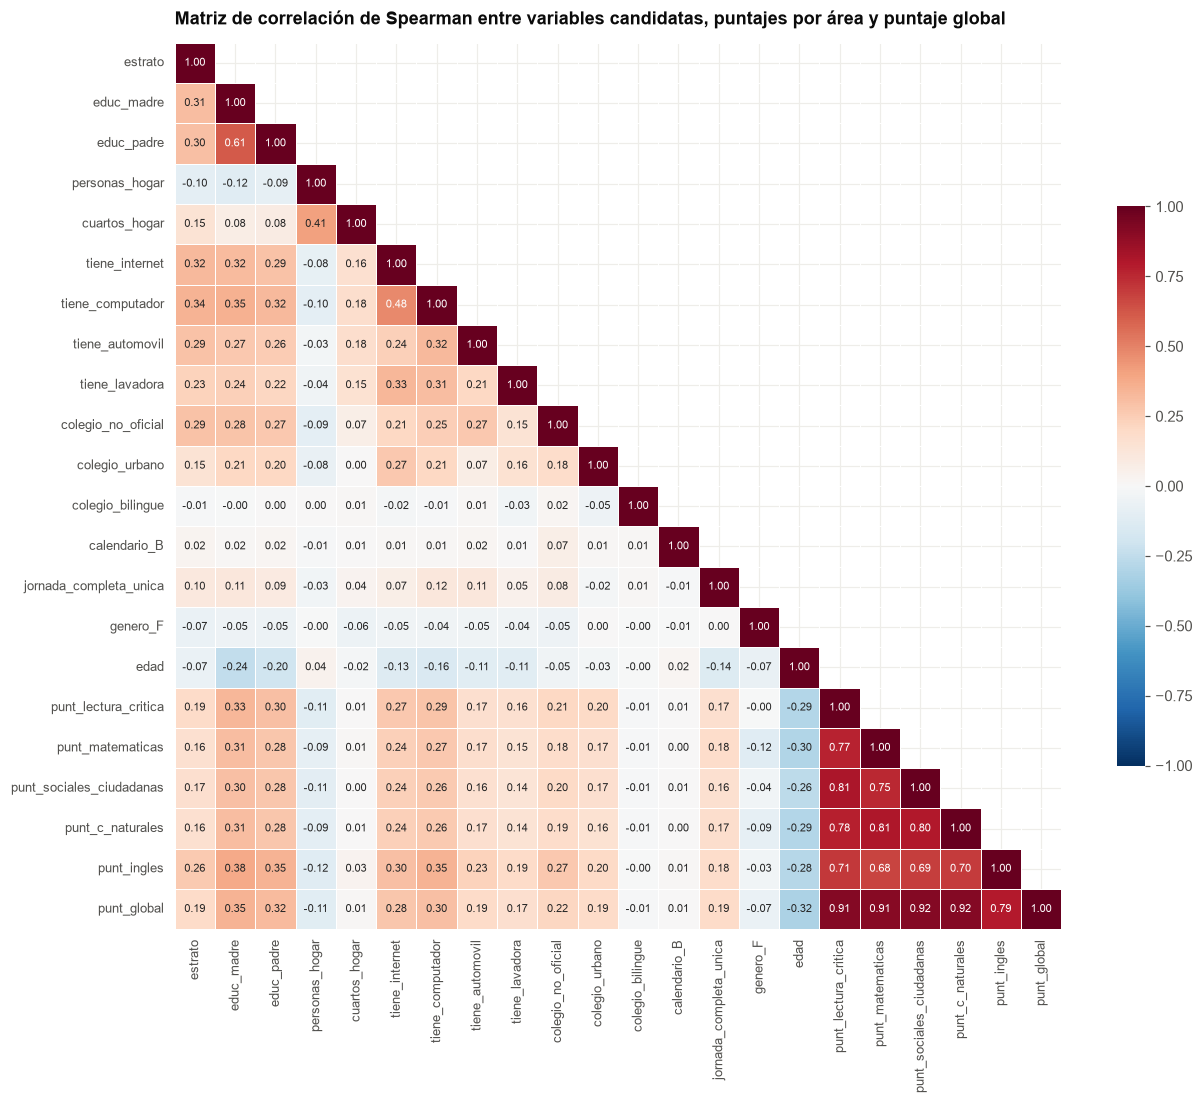

In [33]:
EDU_NIVEL = {"Ninguno": 0, "Primaria incompleta": 1, "Primaria completa": 2,
             "Secundaria (Bachillerato) incompleta": 3, "Secundaria (Bachillerato) completa": 4,
             "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
             "Educación profesional incompleta": 7, "Educación profesional completa": 8, "Postgrado": 9}
ESTRATO_NIVEL = {"Sin Estrato": 0, **{f"Estrato {i}": i for i in range(1, 7)}}
PERSONAS_NIVEL = {"1 a 2": 1, "3 a 4": 2, "5 a 6": 3, "7 a 8": 4, "9 o más": 5}
CUARTOS_NIVEL = {"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5, "Seis o mas": 6}

def binaria(col, positivo):
    return df[col].map(lambda v: np.nan if pd.isna(v) else float(v == positivo))

num = pd.DataFrame({
    "estrato": df["fami_estratovivienda"].astype(object).map(ESTRATO_NIVEL),
    "educ_madre": df["fami_educacionmadre"].astype(object).map(EDU_NIVEL),
    "educ_padre": df["fami_educacionpadre"].astype(object).map(EDU_NIVEL),
    "personas_hogar": df["fami_personashogar"].astype(object).map(PERSONAS_NIVEL),
    "cuartos_hogar": df["fami_cuartoshogar"].astype(object).map(CUARTOS_NIVEL),
    "tiene_internet": binaria("fami_tieneinternet", "Si"),
    "tiene_computador": binaria("fami_tienecomputador", "Si"),
    "tiene_automovil": binaria("fami_tieneautomovil", "Si"),
    "tiene_lavadora": binaria("fami_tienelavadora", "Si"),
    "colegio_no_oficial": binaria("cole_naturaleza", "NO OFICIAL"),
    "colegio_urbano": binaria("cole_area_ubicacion", "URBANO"),
    "colegio_bilingue": binaria("cole_bilingue", "S"),
    "calendario_B": binaria("cole_calendario", "B"),
    "jornada_completa_unica": df["cole_jornada"].isin(["COMPLETA", "UNICA"]).astype(float),
    "genero_F": binaria("estu_genero", "F"),
    "edad": df["edad"],
    "punt_lectura_critica": df["punt_lectura_critica"],
    "punt_matematicas": df["punt_matematicas"],
    "punt_sociales_ciudadanas": df["punt_sociales_ciudadanas"],
    "punt_c_naturales": df["punt_c_naturales"],
    "punt_ingles": df["punt_ingles"],
    "punt_global": df["punt_global"],
})

corr = num.corr(method="spearman")
ranking = corr["punt_global"].drop("punt_global").sort_values(key=np.abs, ascending=False)
print("Correlación de Spearman con punt_global (ordenada por magnitud):")
display(ranking.round(3).to_frame("rho").T)

fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, square=True, linewidths=0.4, cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Matriz de correlación de Spearman entre variables candidatas, puntajes por área y puntaje global")
ax.tick_params(axis="both", labelsize=8.5)
save_fig(fig, "correlation_matrix")
plt.show()

El contraste que se buscaba documentar es evidente, ya que los puntajes por área correlacionan entre 0,91 y 0,92 con el global (0,79 inglés) mientras que ninguna variable explicativa legítima supera 0,35. Entre estas últimas, el orden por magnitud es: educación de la madre (0,35), edad (−0,32), educación del padre (0,32), computador (0,30), internet (0,28), colegio no oficial (0,22), estrato, colegio urbano, jornada completa o única y automóvil (0,19 cada una), lavadora (0,17), personas en el hogar (−0,11) y género (−0,07). Colegio bilingüe, cuartos del hogar y calendario B no muestran asociación monótona (|ρ| ≤ 0,01), aunque para cuartos ya se vio que la relación existe y es en forma de U.

La matriz también muestra que las variables del hogar están correlacionadas entre sí, ya que educación de la madre y del padre, estrato y tenencia de bienes miden facetas del mismo nivel socioeconómico. Esa multicolinealidad no afecta a los modelos de árboles, pero sí a la lectura de los coeficientes de un modelo lineal, como se ve en la celda siguiente.

Las variables del hogar están correlacionadas entre sí (estrato, educación de los padres y tenencia de bienes miden facetas del mismo nivel socioeconómico), por ende, para tener una primera idea de cuánta varianza del puntaje explica el conjunto de variables candidatas, se ajusta una regresión lineal exploratoria sobre las variables codificadas, excluyendo los puntajes por área, usando una muestra aleatoria y una partición simple.

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

PREDICTORAS = [c for c in num.columns if not c.startswith("punt_")]
muestra = num[PREDICTORAS + ["punt_global"]].dropna().sample(200_000, random_state=RANDOM_STATE)
X_tr, X_te, y_tr, y_te = train_test_split(muestra[PREDICTORAS], muestra["punt_global"],
                                          test_size=0.2, random_state=RANDOM_STATE)
lineal = LinearRegression().fit(X_tr, y_tr)
pred = lineal.predict(X_te)
print(f"Filas completas usadas: {len(muestra):,} (80 % entrenamiento / 20 % prueba)")
print(f"R² en prueba : {r2_score(y_te, pred):.3f}")
print(f"MAE en prueba: {mean_absolute_error(y_te, pred):.1f} puntos "
      f"(desviación del puntaje: {y_te.std():.1f}; MAE de predecir la media: "
      f"{mean_absolute_error(y_te, np.full_like(y_te, y_tr.mean())):.1f})")

coefs = pd.Series(lineal.coef_, index=PREDICTORAS).sort_values(key=np.abs, ascending=False)
display(coefs.round(2).to_frame("coeficiente (puntos por unidad)").T)

Filas completas usadas: 200,000 (80 % entrenamiento / 20 % prueba)
R² en prueba : 0.242
MAE en prueba: 36.5 puntos (desviación del puntaje: 51.5; MAE de predecir la media: 42.6)


,colegio_no_oficial,tiene_computador,jornada_completa_unica,tiene_internet,colegio_urbano,genero_F,colegio_bilingue,tiene_automovil,cuartos_hogar,educ_madre,edad,educ_padre,personas_hogar,calendario_B,estrato,tiene_lavadora
coeficiente (puntos por unidad),14.36,11.42,11.12,10.09,9.31,-4.87,-3.82,3.70,-3.39,3.04,-2.93,2.34,-1.29,0.61,-0.56,-0.33


Con las variables codificadas de forma aditiva, una regresión lineal alcanza un **R² de 0,242 y un MAE de 36,5 puntos** en la muestra de prueba, frente a 42,6 puntos de predecir siempre la media reduciendo el error un 14 %. Es una cota modesta pero coherente con la literatura sobre determinantes del rendimiento en Saber 11, donde las variables socioeconómicas y del colegio explican típicamente entre un cuarto y un tercio de la varianza, el resto corresponde a la capacidad, el esfuerzo y la preparación individual, que el cuestionario no mide.

Los coeficientes ratifican las secciones anteriores y revelan la multicolinealidad, puesto que al estudiar en colegio no oficial (+14,4), tener computador (+11,4), jornada completa o única (+11,1), tener internet (+10,1) y colegio urbano (+9,3) son los mayores efectos por unidad. Cada nivel educativo de la madre suma 3,0 puntos (27 entre *Ninguno* y *Posgrado*) y cada año de edad resta 2,9. El estrato, en cambio, queda con un coeficiente negativo casi nulo (−0,56) porque los bienes del hogar y la educación de los padres absorben su información, lo que confirma que como variable individual es la menos confiable del bloque. Para la fase 2 el objetivo razonable es superar este R² con una partición definitiva, variables derivadas.

## 11. Hallazgos y decisiones para la fase 2

El análisis exploratorio deja un conjunto de hallazgos que se traducen directamente en decisiones de preparación de datos e ingeniería de variables. Se resumen en la tabla, junto con la evidencia que las sustenta.

| # | Hallazgo | Evidencia | Decisión para la fase 2 |
|---|---|---|---|
| 1 | El archivo del portal contiene cada registro dos veces. | 533.096 duplicados exactos (50,01 %); 532.792 consecutivos únicos. | Eliminar duplicados **antes** de cualquier partición, para que un mismo estudiante no caiga en entrenamiento y prueba. |
| 2 | El puntaje global es una función exacta de los puntajes por área. | Fórmula verificada en el 100 % de los registros; correlaciones de 0,91 a 0,92. | Excluir `punt_*` por área y `desemp_ingles` del conjunto de variables explicativas (fuga de información). |
| 3 | La ausencia del cuestionario es informativa. | Sin cuestionario: 229,1 puntos; con cuestionario: 250,6. | No eliminar filas con faltantes; codificar *no respondió* como categoría y agregar un indicador de cuestionario incompleto. |
| 4 | Columnas sin información o redundantes. | `periodo` y `estu_estudiante` constantes; `estu_estadoinvestigacion` y `estu_privado_libertad` > 99,9 % en un valor; códigos y nombres con miles de niveles; lugar de presentación y de residencia replican la ubicación del colegio. | Descartar constantes, casi constantes, identificadores, nombres y las columnas de presentación/residencia; conservar departamento y municipio del colegio. |
| 5 | La educación de los padres y la tenencia de internet y computador son las variables del hogar más asociadas al puntaje. | ρ = 0,35 (madre), 0,32 (padre), 0,30 (computador), 0,28 (internet); rango de 96 puntos entre *Ninguno* y *Posgrado*. | Codificar la educación de los padres como ordinal (0 a 9) y mantener *No sabe* como nivel propio; bienes como binarias. |
| 6 | El estrato se quiebra en los niveles altos. | Estratos 5 y 6 promedian 261,4 y 245,1, por debajo del 4 (267,4), con desviaciones de 67 a 70. | Probar el estrato como nominal o agrupar 4 a 6; no confiar en él como único indicador socioeconómico. |
| 7 | Personas y cuartos del hogar tienen relación en forma de U. | Máximo en 3 a 4 personas (257,1) y tres cuartos (255,8); caída en ambos extremos. | Crear la variable derivada **personas por cuarto** (hacinamiento) y tratar ambas como categóricas, no numéricas. |
| 8 | La edad es un marcador fuerte de extraedad y educación de adultos. | De 265 puntos a los 16-17 años a 199,6 de 26 en adelante; ρ = −0,32. | Conservar la edad numérica y una variable de *extraedad* (≥ 19 años); descartar `estu_tipodocumento`, que la duplica. |
| 9 | Jornada, naturaleza y área del colegio aportan brechas de 26 a 70 puntos, con interacción naturaleza × área. | Completa 280,8 vs. nocturna 210,6; no oficial 272,6 vs. oficial 243,6; privado rural 291,1 > oficial rural 224,5. | Codificar jornada, naturaleza, área y carácter como nominales; incluir la interacción naturaleza × área para los modelos lineales. |
| 10 | El indicador de colegio bilingüe no es confiable. | 18 % de faltantes y promedio menor que los no bilingües. | Descartarlo o conservarlo solo como categoría con *no reportado*. |
| 11 | Brecha regional de 64 puntos con departamentos muy pequeños. | Bogotá 270,2 vs. Chocó 206,1; Guainía, Vaupés y San Andrés con menos de 600 estudiantes. | Departamento con *one-hot* o codificación por objetivo suavizada; municipio solo con codificación por objetivo calculada en entrenamiento. |
| 12 | Las variables candidatas explican alrededor de un cuarto de la varianza de forma lineal. | R² = 0,242, MAE = 36,5 frente a 42,6 de la media. | Fijar como referencia (*baseline*) una regresión lineal regularizada y como meta de la fase 3 superar ese R² con modelos no lineales. |

Con estas decisiones, el conjunto de trabajo para la fase 2 queda en 532.792 registros y cerca de 22 variables explicativas (3 del estudiante, 9 del hogar, 7 del colegio, 2 geográficas y las derivadas), con `punt_global` como objetivo.

## 12. Conclusiones

*   El conjunto *Resultados únicos Saber 11* del periodo 2022-4 es apto para el problema planteado ya que es público, con licencia abierta, tiene una variable objetivo continua y bien comportada (media 250,1, desviación 51,8, asimetría 0,28) y reúne para 532.792 estudiantes, información del hogar, del colegio y de la geografía que existe antes de la prueba.

*   La verificación de calidad fue tan importante como el análisis de las variables, dado que, la mitad de las filas descargadas eran duplicados exactos y el puntaje global resultó ser una función determinista de los puntajes por área. Ambos hallazgos, de pasarse por alto, habrían producido métricas de modelado ficticias.

*   Las tres hipótesis de trabajo reciben respaldo preliminar. El nivel socioeconómico del hogar, en particular la educación de los padres y el acceso a internet y computador, concentra las asociaciones más altas (H1), las características del colegio, sobre todo la jornada y la naturaleza aportan brechas propias de 29 a 70 puntos y una interacción con el área (H2) y el departamento del colegio introduce una brecha de 64 puntos entre Bogotá y Chocó que ninguna variable individual explica por sí sola (H3).

*   Ninguna variable aislada correlaciona más de 0,35 con el puntaje y una regresión lineal aditiva explica el 24,2 % de la varianza con un error absoluto medio de 36,5 puntos. Ese es el punto de partida honesto del proyecto, el modelo de referencia de la fase 2 deberá reproducirlo con la partición definitiva y los modelos de la fase 3 deberán superarlo capturando las relaciones no lineales y las interacciones que el análisis exploratorio dejó identificadas.

*   Los valores faltantes no son aleatorios (quienes no responden el cuestionario obtienen 21,5 puntos menos) y varias variables ordinales no se comportan como tales (estrato, personas y cuartos del hogar). La estrategia de preparación debe conservar esa información en lugar de imputarla o descartarla, lo que define el plan de limpieza e ingeniería de variables de la siguiente actividad.